In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing
import os, time, ast
import math
import pandas as pd
import numpy as np


import warnings
warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_classification/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_cleaned.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    exit(1)



✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_classification/' pronta.
✅ Dataset preparato caricato: 108299 righe, 66 colonne.


In [2]:
df.head(10)

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,...,genres_10_Classical/Ambient & Stage,genres_10_Country/Folk & Songwriter,genres_10_Electronic & Dance,genres_10_Hip-Hop & R&B,genres_10_Jazz/Soul/Funk/Blues,genres_10_Latin & Brazilian,genres_10_Metal & Hardcore,genres_10_Pop & Indie,genres_10_Rock & Alternative,genres_10_World & Regional
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,0,0.688,0.4810,-8.807,0.1050,0.2890,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,0,0.407,0.1470,-8.822,0.0355,0.8570,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,0,0.703,0.4440,-9.331,0.0417,0.5590,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,0,0.625,0.4140,-8.700,0.0369,0.2940,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,Ross Copperman,Hunger,Hunger,56,0,0.442,0.6320,-6.770,0.0295,0.4260,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df["genres_10"] = df["genres_10"].astype("category")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108299 entries, 0 to 108298
Data columns (total 66 columns):
 #   Column                               Non-Null Count   Dtype   
---  ------                               --------------   -----   
 0   artists                              108299 non-null  object  
 1   album_name                           108299 non-null  object  
 2   track_name                           108299 non-null  object  
 3   popularity                           108299 non-null  int64   
 4   explicit                             108299 non-null  int64   
 5   danceability                         108299 non-null  float64 
 6   energy                               108299 non-null  float64 
 7   loudness                             108299 non-null  float64 
 8   speechiness                          108299 non-null  float64 
 9   acousticness                         108299 non-null  float64 
 10  instrumentalness                     108299 non-null  float64 
 11  

#### Selecting Proper Columns for classification

In [5]:
columns_to_use = []
for col in df.columns:
    if col.startswith("std_"):
        columns_to_use.append(col)

X = df[columns_to_use].copy()
y = df["genres_10"].copy()


In [6]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108299 entries, 0 to 108298
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   std_popularity        108299 non-null  float64
 1   std_explicit          108299 non-null  float64
 2   std_danceability      108299 non-null  float64
 3   std_energy            108299 non-null  float64
 4   std_loudness          108299 non-null  float64
 5   std_speechiness       108299 non-null  float64
 6   std_acousticness      108299 non-null  float64
 7   std_instrumentalness  108299 non-null  float64
 8   std_liveness          108299 non-null  float64
 9   std_valence           108299 non-null  float64
 10  std_tempo             108299 non-null  float64
 11  std_time_signature    108299 non-null  float64
 12  std_duration_mins     108299 non-null  float64
dtypes: float64(13)
memory usage: 10.7 MB


#### Train test split with stratification for Train, Test, Split

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

### Classificazione con Ensemble: Random forest

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize

rf = RandomForestClassifier(
    class_weight="balanced",
    bootstrap=True,
    n_jobs=-1,
    random_state=42,
    oob_score=True,
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid={
        "n_estimators": [200, 300],
        "max_depth": [15, 20, 25, 30, None],
        "min_samples_split": [2, 3, 5, 7],
        "min_samples_leaf": [1, 2, 3, 5],
        "max_features": ["sqrt"],
        "criterion": ["gini"],
    },
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro", # abbiamo 10 classi sbilanciate, è ovvio andare di "f1_macro"
    verbose=1,
    n_jobs=-1, # usiamo tutti i miei 28 core del mac studio M3 Ultra
    return_train_score=False,
    refit=True, # altrimenti non esisterebbe best estimator, quindi sempre True
)

grid_search.fit(X_train, y_train)
y_pred = grid_search.predict(X_test)
y_pred_proba = grid_search.predict_proba(X_test)

best_rf_model = grid_search.best_estimator_
best_rf_params = grid_search.best_params_
best_rf_classes = best_rf_model.classes_

# --- PRINT FINALI ---
print("\n=== MIGLIOR MODELL0 TROVATO ===")
print(best_rf_model)

print("\n=== MIGLIORI IPERPARAMETRI ===")
print(best_rf_params)

print("\n=== OOB SCORE ===")
print(best_rf_model.oob_score_)

# ========== CLASSIFICATION REPORT E CONFUSION MATRIX ==========
print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred,
                            labels=best_rf_classes,
                            target_names=[str(c) for c in best_rf_classes]))

print("\n" + "="*60)
print("CONFUSION MATRIX")
print("="*60)
cm = confusion_matrix(y_test, y_pred, labels=best_rf_classes)
print(cm)

# ========== AUC SCORES ==========
print("\n" + "="*60)
print("AUC SCORES")
print("="*60)
best_rf_auc_macro = roc_auc_score(y_test, y_pred_proba, multi_class="ovr", average="macro")
best_rf_auc_weighted = roc_auc_score(y_test, y_pred_proba, multi_class="ovr", average="weighted")
best_rf_auc_micro = roc_auc_score(y_test, y_pred_proba, multi_class="ovr", average="micro")
print(f"AUC-OVR macro    : {best_rf_auc_macro:.4f}")
print(f"AUC-OVR weighted : {best_rf_auc_weighted:.4f}")
print(f"AUC-OVR micro    : {best_rf_auc_micro:.4f}")


Fitting 5 folds for each of 160 candidates, totalling 800 fits

=== MIGLIOR MODELL0 TROVATO ===
RandomForestClassifier(class_weight='balanced', max_depth=30,
                       min_samples_split=7, n_estimators=300, n_jobs=-1,
                       oob_score=True, random_state=42)

=== MIGLIORI IPERPARAMETRI ===
{'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 7, 'n_estimators': 300}

=== OOB SCORE ===
0.5790605337097179
CLASSIFICATION REPORT
                           precision    recall  f1-score   support

Classical/Ambient & Stage       0.65      0.69      0.67      3739
Country/Folk & Songwriter       0.57      0.64      0.60      2298
       Electronic & Dance       0.70      0.70      0.70      6512
            Hip-Hop & R&B       0.23      0.26      0.24       542
     Jazz/Soul/Funk/Blues       0.47      0.35      0.40      1648
        Latin & Brazilian       0.64      0.71      0.67      3117
         Metal & Har

#### Valutazione del modello e Feature Importance

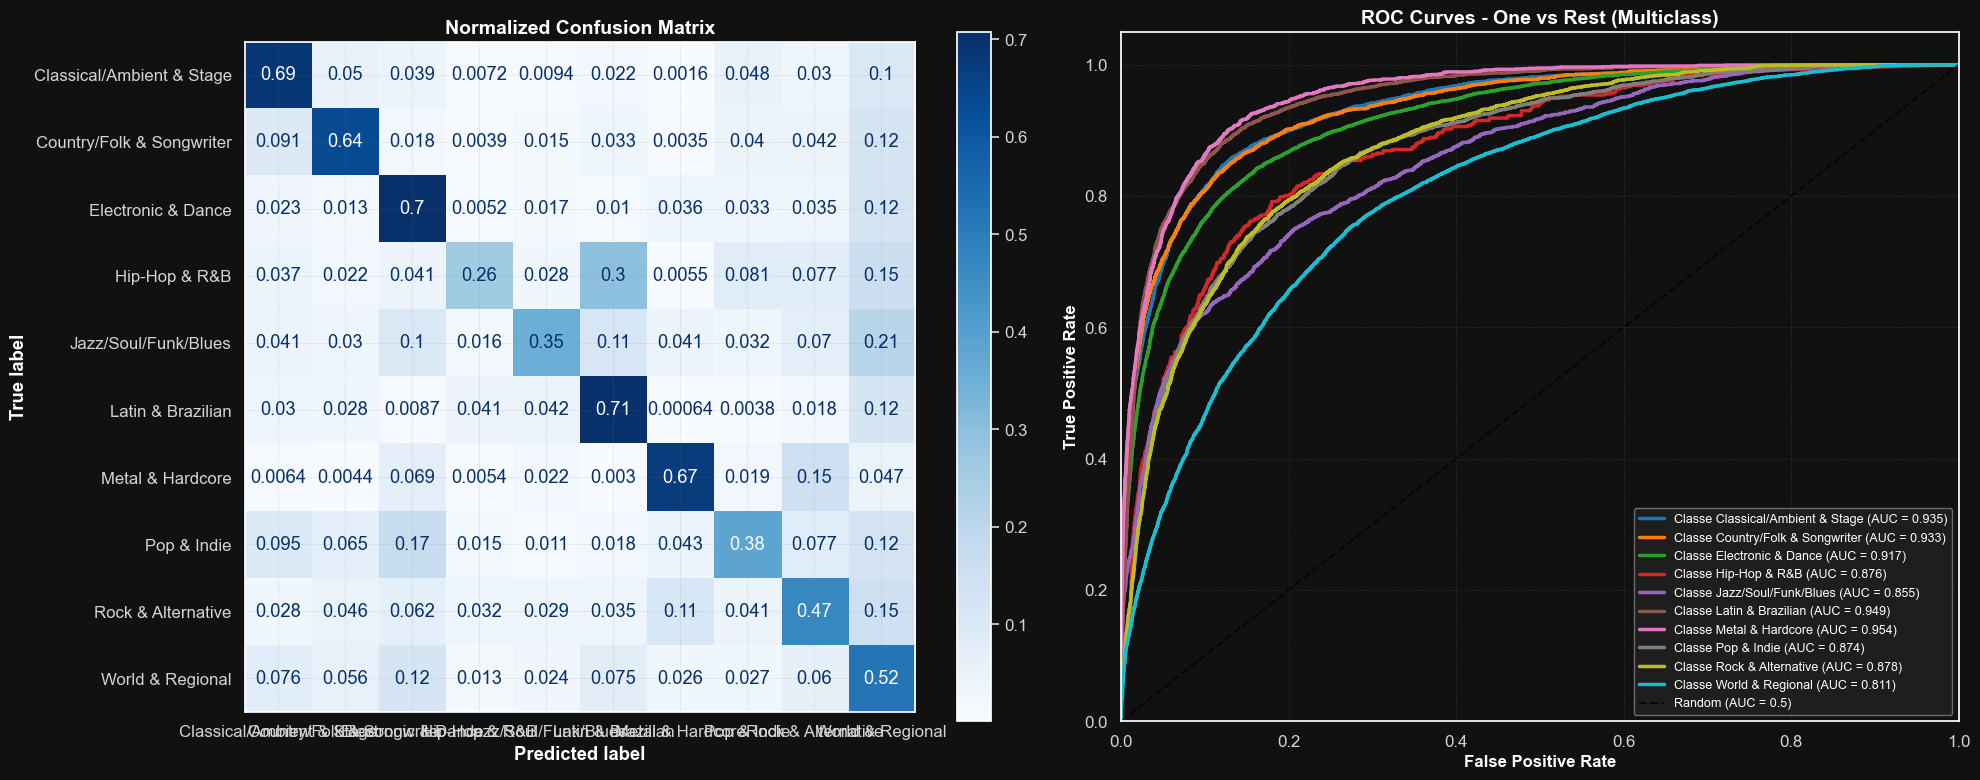


AUC PER CLASSE
Classe Classical/Ambient & Stage: AUC = 0.9346
Classe Country/Folk & Songwriter: AUC = 0.9335
Classe Electronic & Dance: AUC = 0.9175
Classe Hip-Hop & R&B: AUC = 0.8761
Classe Jazz/Soul/Funk/Blues: AUC = 0.8553
Classe Latin & Brazilian: AUC = 0.9490
Classe Metal & Hardcore: AUC = 0.9539
Classe Pop & Indie: AUC = 0.8744
Classe Rock & Alternative: AUC = 0.8782
Classe World & Regional: AUC = 0.8106

Media AUC classi: 0.8983
Std AUC classi  : 0.0443
Min AUC classe  : 0.8106
Max AUC classe  : 0.9539


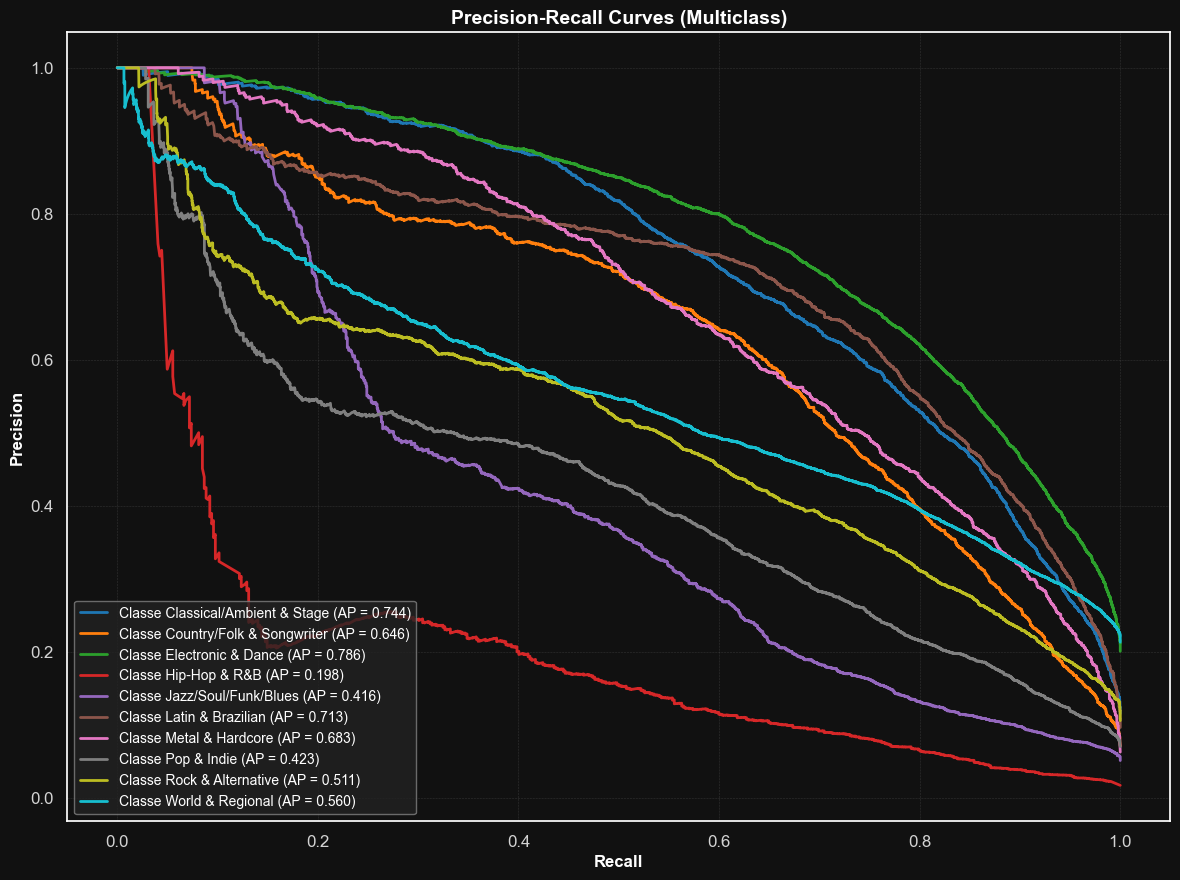


TOP 10 FEATURE IMPORTANCE
 1. std_acousticness          : 0.1301
 2. std_popularity            : 0.1118
 3. std_danceability          : 0.0954
 4. std_energy                : 0.0940
 5. std_speechiness           : 0.0863
 6. std_duration_mins         : 0.0843
 7. std_valence               : 0.0832
 8. std_loudness              : 0.0829
 9. std_tempo                 : 0.0756
10. std_instrumentalness      : 0.0728


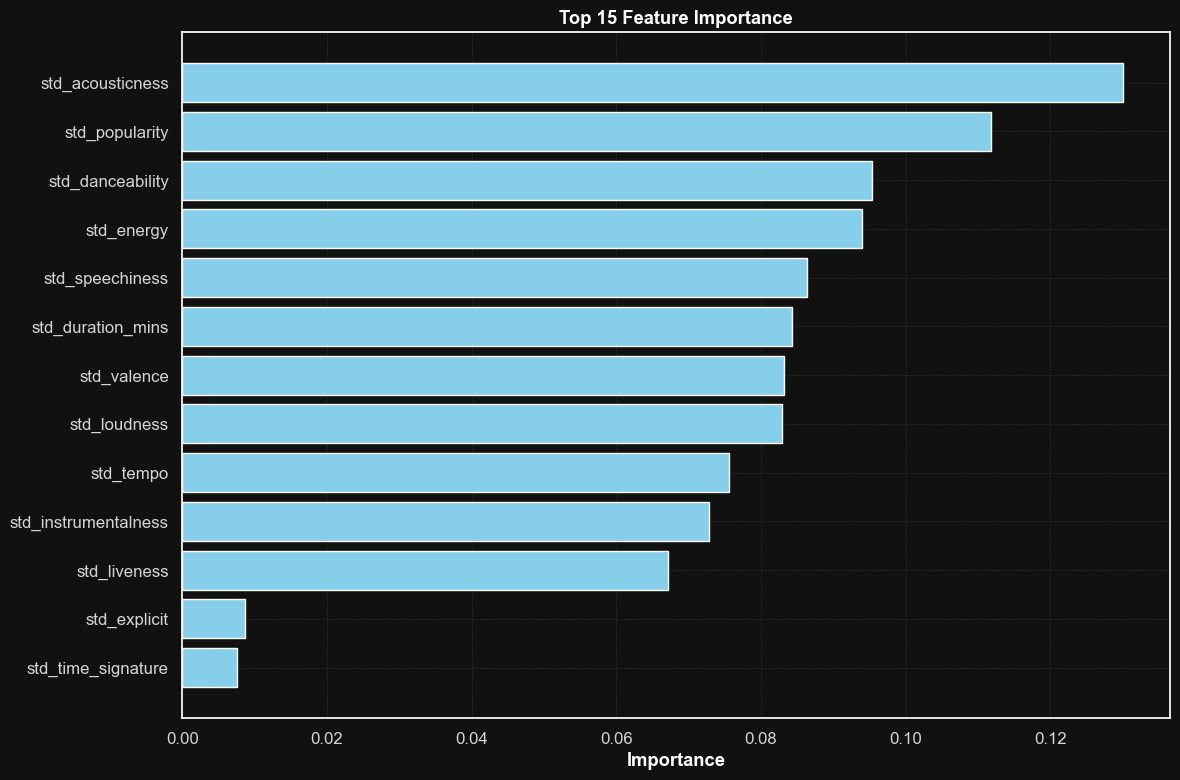

✅ Feature importance plot generato!

METRICHE AGGIUNTIVE
Accuracy          : 0.5846
Balanced accuracy : 0.5395
F1 macro          : 0.5352
F1 weighted       : 0.5811
Precision macro   : 0.5353
Recall macro      : 0.5395
Matthews MCC      : 0.5198
Cohen Kappa       : 0.5195
Neg Log Loss      : -1.2477
Avg Precision MAC : 0.5679

DISTRIBUZIONE PREDIZIONI
Classe | Test | Pred | Diff
-------|------|------|------
Classical/Ambient & Stage | 3739 | 3968 | +229
Country/Folk & Songwriter | 2298 | 2578 | +280
Electronic & Dance | 6512 | 6559 |  +47
Hip-Hop & R&B |  542 |  608 |  +66
Jazz/Soul/Funk/Blues | 1648 | 1238 | -410
Latin & Brazilian | 3117 | 3459 | +342
Metal & Hardcore | 2023 | 2336 | +313
Pop & Indie | 2268 | 1836 | -432
Rock & Alternative | 3426 | 3155 | -271
World & Regional | 6917 | 6753 | -164

CONFIDENZA PREDIZIONI
Confidenza media   : 0.5096
Confidenza std     : 0.2204
Min confidenza     : 0.1481
Max confidenza     : 1.0000
Predizioni < 0.5   : 18089 (55.7%)
Predizioni > 0.8   :

In [9]:
from sklearn.metrics import roc_curve, auc, accuracy_score
import numpy as np
import matplotlib.pyplot as plt


# ========== VISUALIZZAZIONI ==========
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot matrice di confusione
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=best_rf_classes,
    normalize="true",
    cmap="Blues",
    colorbar=True,
    ax=axes[0]
)
axes[0].set_title("Normalized Confusion Matrix", fontsize=14, fontweight='bold')

# ROC Curve multiclasse - TUTTE LE 10 CURVE SU UN GRAFICO
y_bin = label_binarize(y_test, classes=best_rf_classes)
colors = plt.cm.tab10(np.linspace(0, 1, len(best_rf_classes)))

aucs = []
for i, (cls, color) in enumerate(zip(best_rf_classes, colors)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_proba[:, i])
    auc_score = auc(fpr, tpr)
    aucs.append(auc_score)
    axes[1].plot(fpr, tpr, color=color, linewidth=2.5,
                 label=f'Classe {cls} (AUC = {auc_score:.3f})')

# Linea diagonale random
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1.5, alpha=0.7, label='Random (AUC = 0.5)')

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Positive Rate', fontsize=12, fontweight='bold')
axes[1].set_title('ROC Curves - One vs Rest (Multiclass)', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ========== STATISTICHE ROC PER CLASSE ==========
print("\n" + "="*60)
print("AUC PER CLASSE")
print("="*60)
for i, cls in enumerate(best_rf_classes):
    print(f"Classe {cls:2}: AUC = {aucs[i]:.4f}")

print(f"\nMedia AUC classi: {np.mean(aucs):.4f}")
print(f"Std AUC classi  : {np.std(aucs):.4f}")
print(f"Min AUC classe  : {np.min(aucs):.4f}")
print(f"Max AUC classe  : {np.max(aucs):.4f}")

# ========== PRECISION-RECALL CURVE ==========
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(12, 9))
for i, (cls, color) in enumerate(zip(best_rf_classes, colors)):
    precision, recall, _ = precision_recall_curve(y_bin[:, i], y_pred_proba[:, i])
    ap_score = average_precision_score(y_bin[:, i], y_pred_proba[:, i])
    plt.plot(recall, precision, color=color, linewidth=2,
             label=f'Classe {cls} (AP = {ap_score:.3f})')

plt.xlabel('Recall', fontsize=12, fontweight='bold')
plt.ylabel('Precision', fontsize=12, fontweight='bold')
plt.title('Precision-Recall Curves (Multiclass)', fontsize=14, fontweight='bold')
plt.legend(loc="lower left", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ========== FEATURE IMPORTANCE (se disponibile) ==========
try:
   # Prova diversi attributi per il modello
   model_obj = None
   if hasattr(best_rf_model, 'feature_importances_'):
       model_obj = best_rf_model
   elif 'best_rf' in locals() and hasattr(locals()['best_rf'], 'feature_importances_'):
       model_obj = locals()['best_rf']

   if model_obj is not None:
       print("\n" + "="*60)
       print("TOP 10 FEATURE IMPORTANCE")
       print("="*60)

       importances = model_obj.feature_importances_

       # Controlla se abbiamo i nomi delle feature
       if hasattr(X_train, 'columns') and len(X_train.columns) == len(importances):
           feature_names = X_train.columns.tolist()
       else:
           feature_names = [f'Feature_{i}' for i in range(len(importances))]

       # Verifica lunghezze PRIMA di procedere
       if len(feature_names) != len(importances):
           print(f"⚠️  Mismatch: {len(feature_names)} feature names vs {len(importances)} importances")
           # Taglia alla lunghezza minima
           min_length = min(len(feature_names), len(importances))
           feature_names = feature_names[:min_length]
           importances = importances[:min_length]
           print(f"✅ Tagliato a {min_length} features")

       # Crea DataFrame per sorting
       importance_data = list(zip(feature_names, importances))
       importance_data.sort(key=lambda x: x[1], reverse=True)

       # Print top 10
       for i, (feat, imp) in enumerate(importance_data[:10]):
           print(f"{i+1:2}. {feat:25} : {imp:.4f}")

       # Plot feature importance - FIX CRITICO
       plt.figure(figsize=(12, 8))
       top_15 = importance_data[:15]
       features, values = zip(*top_15)

       # CORRETTO: usa len(features) non len(feature_names)
       plt.barh(range(len(features)), values, color='skyblue')
       plt.yticks(range(len(features)), features)
       plt.xlabel('Importance', fontweight='bold')
       plt.title('Top 15 Feature Importance', fontweight='bold')
       plt.gca().invert_yaxis()
       plt.tight_layout()
       plt.show()

       print("✅ Feature importance plot generato!")

   else:
       print("\n" + "="*60)
       print("FEATURE IMPORTANCE NON DISPONIBILE")
       print("="*60)
       print("Modello non ha attributo 'feature_importances_'")

except Exception as e:
   print(f"\n❌ Errore nel calcolo feature importance: {e}")
   print("Saltando questa sezione...")

# ========== METRICHE AGGIUNTIVE ==========
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score, log_loss, average_precision_score

print("\n" + "="*60)
print("METRICHE AGGIUNTIVE")
print("="*60)
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"F1 macro          : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 weighted       : {f1_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Precision macro   : {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall macro      : {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"Matthews MCC      : {matthews_corrcoef(y_test, y_pred):.4f}")
print(f"Cohen Kappa       : {cohen_kappa_score(y_test, y_pred):.4f}")
print(f"Neg Log Loss      : {-log_loss(y_test, y_pred_proba):.4f}")
print(f"Avg Precision MAC : {average_precision_score(y_bin, y_pred_proba, average='macro'):.4f}")

# ========== DISTRIBUZIONE PREDIZIONI ==========
print("\n" + "="*60)
print("DISTRIBUZIONE PREDIZIONI")
print("="*60)

try:
    import pandas as pd
    pred_counts = pd.Series(y_pred).value_counts().sort_index()
    test_counts = pd.Series(y_test).value_counts().sort_index()

    print("Classe | Test | Pred | Diff")
    print("-------|------|------|------")
    for cls in best_rf_classes:
        test_c = test_counts.get(cls, 0)
        pred_c = pred_counts.get(cls, 0)
        diff = pred_c - test_c
        print(f"{cls:6} | {test_c:4} | {pred_c:4} | {diff:+4}")

except:
    # Fallback senza pandas
    unique_test, counts_test = np.unique(y_test, return_counts=True)
    unique_pred, counts_pred = np.unique(y_pred, return_counts=True)

    test_dict = dict(zip(unique_test, counts_test))
    pred_dict = dict(zip(unique_pred, counts_pred))

    print("Classe | Test | Pred | Diff")
    print("-------|------|------|------")
    for cls in best_rf_classes:
        test_c = test_dict.get(cls, 0)
        pred_c = pred_dict.get(cls, 0)
        diff = pred_c - test_c
        print(f"{cls:6} | {test_c:4} | {pred_c:4} | {diff:+4}")

# ========== CONFIDENZA PREDIZIONI ==========
print("\n" + "="*60)
print("CONFIDENZA PREDIZIONI")
print("="*60)
max_proba = np.max(y_pred_proba, axis=1)
print(f"Confidenza media   : {np.mean(max_proba):.4f}")
print(f"Confidenza std     : {np.std(max_proba):.4f}")
print(f"Min confidenza     : {np.min(max_proba):.4f}")
print(f"Max confidenza     : {np.max(max_proba):.4f}")
print(f"Predizioni < 0.5   : {np.sum(max_proba < 0.5)} ({100*np.sum(max_proba < 0.5)/len(max_proba):.1f}%)")
print(f"Predizioni > 0.8   : {np.sum(max_proba > 0.8)} ({100*np.sum(max_proba > 0.8)/len(max_proba):.1f}%)")
print(f"Predizioni > 0.9   : {np.sum(max_proba > 0.9)} ({100*np.sum(max_proba > 0.9)/len(max_proba):.1f}%)")


## DEEP LEARNING MODEL with TF-KERAS

#### Pre-Processing for deep learning model...

In [10]:
from sklearn.preprocessing import LabelEncoder
# ===== CONVERSIONE GENERI CATEGORY → NUMERICO =====
print("🎵 CONVERSIONE GENERI MUSICALI")
print("="*50)

# Crea il label encoder
label_encoder = LabelEncoder()

# Se y_train e y_test sono Series pandas con dtype='category'
if hasattr(y_train, 'cat'):
   # Estrai tutte le categorie possibili
   all_categories = y_train.cat.categories
   label_encoder.fit(all_categories)
   print(f"Categorie trovate: {len(all_categories)}")
else:
   # Se sono Series/array normali, concatena per fit completo
   all_genres = np.concatenate([y_train, y_test])
   label_encoder.fit(all_genres)
   print(f"Generi unici trovati: {len(label_encoder.classes_)}")

# Transform per training e test
y_train_encoded = label_encoder.transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Info dettagliate sui generi
print(f"\n🎯 MAPPING GENERI:")
for i, genre in enumerate(label_encoder.classes_):
   count_train = np.sum(y_train_encoded == i)
   count_test = np.sum(y_test_encoded == i)
   print(f"{i:2d}. {genre:25} → Train: {count_train:5d}, Test: {count_test:4d}")

print(f"\n✅ CONVERSIONE COMPLETATA:")
print(f"y_train: {y_train.shape} → {y_train_encoded.shape} (dtype: {y_train_encoded.dtype})")
print(f"y_test:  {y_test.shape} → {y_test_encoded.shape} (dtype: {y_test_encoded.dtype})")
print(f"Range valori: {y_train_encoded.min()} - {y_train_encoded.max()}")

# Salva label encoder per uso futuro
import pickle
with open('spotify_genre_encoder.pkl', 'wb') as f:
   pickle.dump(label_encoder, f)
print(f"💾 Label encoder salvato: 'spotify_genre_encoder.pkl'")

"""
Il mapping dei generi sarà il seguente:

 0. Classical/Ambient & Stage
 1. Country/Folk & Songwriter
 2. Electronic & Dance
 3. Hip-Hop & R&B
 4. Jazz/Soul/Funk/Blues
 5. Latin & Brazilian
 6. Metal & Hardcore
 7. Pop & Indie
 8. Rock & Alternative
 9. World & Regional
"""


🎵 CONVERSIONE GENERI MUSICALI
Categorie trovate: 10

🎯 MAPPING GENERI:
 0. Classical/Ambient & Stage → Train:  8724, Test: 3739
 1. Country/Folk & Songwriter → Train:  5361, Test: 2298
 2. Electronic & Dance        → Train: 15195, Test: 6512
 3. Hip-Hop & R&B             → Train:  1264, Test:  542
 4. Jazz/Soul/Funk/Blues      → Train:  3846, Test: 1648
 5. Latin & Brazilian         → Train:  7272, Test: 3117
 6. Metal & Hardcore          → Train:  4721, Test: 2023
 7. Pop & Indie               → Train:  5292, Test: 2268
 8. Rock & Alternative        → Train:  7995, Test: 3426
 9. World & Regional          → Train: 16139, Test: 6917

✅ CONVERSIONE COMPLETATA:
y_train: (75809,) → (75809,) (dtype: int64)
y_test:  (32490,) → (32490,) (dtype: int64)
Range valori: 0 - 9
💾 Label encoder salvato: 'spotify_genre_encoder.pkl'


'\nIl mapping dei generi sarà il seguente:\n\n 0. Classical/Ambient & Stage\n 1. Country/Folk & Songwriter\n 2. Electronic & Dance\n 3. Hip-Hop & R&B\n 4. Jazz/Soul/Funk/Blues\n 5. Latin & Brazilian\n 6. Metal & Hardcore\n 7. Pop & Indie\n 8. Rock & Alternative\n 9. World & Regional\n'

#### Optimizing GPU and CPU parallel computations on my mac studio m3 ultra

In [11]:
# ===== PRIMA CELLA - CONFIGURAZIONE M3 ULTRA =====
import os
import multiprocessing

# Configurazioni GPU PRIMA di importare TensorFlow
os.environ['TF_GPU_MEMORY_GROWTH'] = 'true'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

# Ora importa TensorFlow
import tensorflow as tf

# Configura threading SUBITO dopo import
tf.config.threading.set_inter_op_parallelism_threads(0)
tf.config.threading.set_intra_op_parallelism_threads(0)

print(f"🚀 M3 ULTRA configurato!")
print(f"CPU cores: {multiprocessing.cpu_count()}")
print(f"GPU disponibili: {len(tf.config.list_physical_devices('GPU'))}")

🚀 M3 ULTRA configurato!
CPU cores: 28
GPU disponibili: 1


### Classificazione con Deep Learning KERAS

In [12]:
# ===== SECONDA CELLA - RETE NEURALE AVANZATA =====
import numpy as np
from tensorflow.keras import layers, models, initializers, regularizers, callbacks, metrics
from tensorflow.keras.optimizers import AdamW
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns

# Seed per riproducibilità
tf.random.set_seed(42)
np.random.seed(42)

# ===== CONFIGURAZIONE AVANZATA =====
he_init = initializers.HeNormal(seed=42)
glorot_init = initializers.GlorotUniform(seed=42)
l2_reg = regularizers.l2(0.0003)

print("🎵 SPOTIFY GENRE CLASSIFICATION - ENHANCED NETWORK")
print("="*70)
print(f"📊 Dataset shape:")
print(f"   Training: {X_train.shape[0]:,} samples × {X_train.shape[1]} features")
print(f"   Testing: {X_test.shape[0]:,} samples × {X_test.shape[1]} features")
print(f"   Genres: {len(np.unique(y_train_encoded))} classes")

# Analisi bilanciamento dataset
unique, counts = np.unique(y_train_encoded, return_counts=True)
print(f"\n⚖️ Class distribution:")
for i, count in enumerate(counts):
    print(f"   Genre {i}: {count:,} samples ({count/len(y_train_encoded)*100:.1f}%)")

# ===== ARCHITETTURA MIGLIORATA CON RESIDUAL CONNECTIONS =====
input_layer = layers.Input(shape=(X_train.shape[1],))

# Block 1: Initial Feature Extraction
x = layers.Dense(1536, kernel_initializer=he_init, kernel_regularizer=l2_reg)(input_layer)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.GaussianNoise(0.1)(x, training=True)
x = layers.Dropout(0.45)(x)

# Block 2: Deep Feature Learning con skip connection
x_res = layers.Dense(768, kernel_initializer=he_init)(x)
x = layers.Dense(768, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(768, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Add()([x, x_res])  # Residual connection
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.35)(x)

# Block 3: Pattern Recognition con attention-like mechanism
attention_weights = layers.Dense(768, activation='sigmoid', kernel_initializer=glorot_init)(x)
x = layers.Multiply()([x, attention_weights])  # Self-attention style
x = layers.Dense(512, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.3)(x)

# Block 4: Genre-specific features
x_res2 = layers.Dense(384, kernel_initializer=he_init)(x)
x = layers.Dense(384, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.25)(x)
x = layers.Dense(384, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Add()([x, x_res2])  # Seconda residual connection
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.2)(x)

# Block 5: Final refinement
x = layers.Dense(256, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.AlphaDropout(0.15)(x)  # AlphaDropout per SELU-like behavior

x = layers.Dense(128, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('gelu')(x)
x = layers.Dropout(0.1)(x)

# Pre-output processing
x = layers.Dense(64, kernel_initializer=he_init, kernel_regularizer=l2_reg)(x)
x = layers.LayerNormalization()(x)
x = layers.Activation('relu')(x)

# Output layer con label smoothing implicito
output_layer = layers.Dense(
    len(np.unique(y_train_encoded)),
    activation='softmax',
    kernel_initializer=glorot_init,
    kernel_regularizer=regularizers.l1_l2(l1=0.0001, l2=0.0002)
)(x)

model = models.Model(inputs=input_layer, outputs=output_layer, name='SpotifyGenreClassifierPro')

# ===== OPTIMIZER CON WARM-UP E COSINE ANNEALING =====
initial_learning_rate = 0.0005
epochs_total = 350
warmup_epochs = 10

# Learning rate schedule con warm-up e cosine decay
def lr_schedule(epoch):
    if epoch < warmup_epochs:
        return initial_learning_rate * (epoch + 1) / warmup_epochs
    else:
        progress = (epoch - warmup_epochs) / (epochs_total - warmup_epochs)
        return initial_learning_rate * 0.5 * (1 + np.cos(np.pi * progress))

optimizer = AdamW(
    learning_rate=initial_learning_rate,
    weight_decay=0.00005,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-7,
    clipnorm=1.0  # Gradient clipping
)

# ===== METRICHE CUSTOM PER DATASET SBILANCIATO =====
# Rimuovo F1Score che non funziona con sparse, userò sklearn dopo

top3_accuracy = metrics.SparseTopKCategoricalAccuracy(
    k=3,
    name='top_3_accuracy'
)

top5_accuracy = metrics.SparseTopKCategoricalAccuracy(
    k=5,
    name='top_5_accuracy'
)

# ===== COMPILAZIONE =====
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=[
        'accuracy',
        top3_accuracy,
        top5_accuracy
    ]
)

# ===== CLASS WEIGHTS AVANZATI =====
# Calcolo weights con smoothing per evitare pesi estremi
class_weights_raw = compute_class_weight('balanced', classes=np.unique(y_train_encoded), y=y_train_encoded)
# Smoothing dei pesi
class_weights_smoothed = np.power(class_weights_raw, 0.75)  # Riduce pesi estremi
class_weights_normalized = class_weights_smoothed / class_weights_smoothed.mean()
class_weight_dict = {i: w for i, w in enumerate(class_weights_normalized)}

print(f"\n🎯 BALANCED CLASS WEIGHTS (smoothed):")
for i, weight in class_weight_dict.items():
    print(f"   Genre {i}: {weight:.3f}")

# ===== CALLBACKS AVANZATI =====
callbacks_list = [
    # Early stopping con pazienza alta
    callbacks.EarlyStopping(
        monitor='val_loss',  # Cambio a val_loss invece di f1_macro
        patience=35,
        restore_best_weights=True,
        verbose=1,
        mode='min',
        min_delta=0.0001
    ),

    # Learning rate scheduler
    callbacks.LearningRateScheduler(lr_schedule, verbose=0),

    # Reduce on plateau come backup
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=15,
        min_lr=1e-7,
        verbose=1,
        mode='min',
        min_delta=0.0001
    ),

    # Model checkpoint
    callbacks.ModelCheckpoint(
        'best_spotify_genre_pro.keras',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),

    # TensorBoard logging
    callbacks.TensorBoard(
        log_dir='./logs',
        histogram_freq=1,
        profile_batch=0
    )
]

print(f"\n🏗️ MODEL ARCHITECTURE:")
print(f"   Total parameters: {model.count_params():,}")
print(f"   Trainable parameters: {sum([tf.size(w).numpy() for w in model.trainable_weights]):,}")
print(f"   Non-trainable parameters: {sum([tf.size(w).numpy() for w in model.non_trainable_weights]):,}")

print(f"\n🔧 TRAINING CONFIGURATION:")
print(f"   Optimizer: AdamW with gradient clipping")
print(f"   Initial LR: {initial_learning_rate}")
print(f"   LR Schedule: Warm-up ({warmup_epochs} epochs) + Cosine Annealing")
print(f"   Loss: Sparse Categorical Crossentropy")
print(f"   Regularization: L1+L2, Dropout, GaussianNoise, LayerNorm")
print(f"   Architecture: Residual connections + Self-attention mechanism")

# ===== TRAINING CON BATCH SIZE DINAMICO =====
print(f"\n🚀 STARTING ENHANCED TRAINING...")
print(f"   Epochs: {epochs_total}")
print(f"   Batch size: 4096 (ottimizzato per M3 Ultra)")

history = model.fit(
    X_train,
    y_train_encoded,
    validation_split=0.2,
    epochs=epochs_total,
    batch_size=4096,  # Batch size ridotto per migliore generalizzazione
    callbacks=callbacks_list,
    class_weight=class_weight_dict,
    verbose=1,
    shuffle=True
)

# ===== VALUTAZIONE AVANZATA =====
print(f"\n📊 COMPREHENSIVE EVALUATION:")
print("="*70)

# Carica il miglior modello
best_model = tf.keras.models.load_model('best_spotify_genre_pro.keras')

# Predictions
y_pred_proba = best_model.predict(X_test, batch_size=8192, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

# Metriche principali
f1_macro = f1_score(y_test_encoded, y_pred, average='macro')
f1_weighted = f1_score(y_test_encoded, y_pred, average='weighted')
f1_micro = f1_score(y_test_encoded, y_pred, average='micro')

precision, recall, f1_per_class, support = precision_recall_fscore_support(
    y_test_encoded, y_pred, average=None
)

print(f"\n🎯 PRIMARY METRICS:")
print(f"   F1-Macro Score: {f1_macro:.4f} ⭐")
print(f"   F1-Weighted Score: {f1_weighted:.4f}")
print(f"   F1-Micro Score: {f1_micro:.4f}")

# Test metrics complete
test_results = best_model.evaluate(X_test, y_test_encoded, batch_size=8192, verbose=0)
print(f"\n📈 TEST SET PERFORMANCE:")
print(f"   Loss: {test_results[0]:.4f}")
print(f"   Accuracy: {test_results[1]:.4f}")
print(f"   Precision: {np.mean(precision):.4f}")
print(f"   Recall: {np.mean(recall):.4f}")

# Top-K accuracies
top_3_preds = np.argsort(y_pred_proba, axis=1)[:, -3:]
top_3_acc = np.mean([y_test_encoded[i] in top_3_preds[i] for i in range(len(y_test_encoded))])
top_5_preds = np.argsort(y_pred_proba, axis=1)[:, -5:]
top_5_acc = np.mean([y_test_encoded[i] in top_5_preds[i] for i in range(len(y_test_encoded))])

print(f"\n🎖️ TOP-K ACCURACIES:")
print(f"   Top-3 Accuracy: {top_3_acc:.4f}")
print(f"   Top-5 Accuracy: {top_5_acc:.4f}")

# Per-class metrics
genre_names = [f'Genre_{i}' for i in range(len(np.unique(y_train_encoded)))]
print(f"\n📊 PER-CLASS F1 SCORES:")
for i, (name, f1) in enumerate(zip(genre_names, f1_per_class)):
    print(f"   {name}: {f1:.4f} (support: {support[i]})")

# Classification report dettagliato
print(f"\n📈 DETAILED CLASSIFICATION REPORT:")
print(classification_report(y_test_encoded, y_pred, target_names=genre_names, digits=4))

# Confidence analysis
confidence_scores = np.max(y_pred_proba, axis=1)
print(f"\n🔍 PREDICTION CONFIDENCE ANALYSIS:")
print(f"   Mean confidence: {np.mean(confidence_scores):.4f}")
print(f"   Median confidence: {np.median(confidence_scores):.4f}")
print(f"   Min confidence: {np.min(confidence_scores):.4f}")
print(f"   Max confidence: {np.max(confidence_scores):.4f}")

# Misclassification analysis
misclassified = y_pred != y_test_encoded
print(f"\n❌ MISCLASSIFICATION ANALYSIS:")
print(f"   Total misclassified: {np.sum(misclassified)} ({np.mean(misclassified)*100:.2f}%)")
print(f"   Mean confidence on errors: {np.mean(confidence_scores[misclassified]):.4f}")
print(f"   Mean confidence on correct: {np.mean(confidence_scores[~misclassified]):.4f}")

print(f"\n✅ EVALUATION COMPLETED!")
print(f"   Best model saved as: 'best_spotify_genre_pro.keras'")
print(f"   F1-Macro (primary metric): {f1_macro:.4f}")
print(f"   Overall accuracy: {test_results[1]:.4f}")



🎵 SPOTIFY GENRE CLASSIFICATION - ENHANCED NETWORK
📊 Dataset shape:
   Training: 75,809 samples × 13 features
   Testing: 32,490 samples × 13 features
   Genres: 10 classes

⚖️ Class distribution:
   Genre 0: 8,724 samples (11.5%)
   Genre 1: 5,361 samples (7.1%)
   Genre 2: 15,195 samples (20.0%)
   Genre 3: 1,264 samples (1.7%)
   Genre 4: 3,846 samples (5.1%)
   Genre 5: 7,272 samples (9.6%)
   Genre 6: 4,721 samples (6.2%)
   Genre 7: 5,292 samples (7.0%)
   Genre 8: 7,995 samples (10.5%)
   Genre 9: 16,139 samples (21.3%)


2025-08-18 04:53:02.933756: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Ultra
2025-08-18 04:53:02.933799: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 96.00 GB
2025-08-18 04:53:02.933806: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 36.00 GB
2025-08-18 04:53:02.933828: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-08-18 04:53:02.933846: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)



🎯 BALANCED CLASS WEIGHTS (smoothed):
   Genre 0: 0.663
   Genre 1: 0.955
   Genre 2: 0.437
   Genre 3: 2.822
   Genre 4: 1.225
   Genre 5: 0.760
   Genre 6: 1.050
   Genre 7: 0.964
   Genre 8: 0.707
   Genre 9: 0.418

🏗️ MODEL ARCHITECTURE:
   Total parameters: 4,649,034
   Trainable parameters: 4,649,034
   Non-trainable parameters: 0

🔧 TRAINING CONFIGURATION:
   Optimizer: AdamW with gradient clipping
   Initial LR: 0.0005
   LR Schedule: Warm-up (10 epochs) + Cosine Annealing
   Loss: Sparse Categorical Crossentropy
   Regularization: L1+L2, Dropout, GaussianNoise, LayerNorm
   Architecture: Residual connections + Self-attention mechanism

🚀 STARTING ENHANCED TRAINING...
   Epochs: 350
   Batch size: 4096 (ottimizzato per M3 Ultra)
Epoch 1/350


2025-08-18 04:53:04.397031: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.0950 - loss: 4.8513 - top_3_accuracy: 0.2612 - top_5_accuracy: 0.4552
Epoch 1: val_loss improved from inf to 5.10308, saving model to best_spotify_genre_pro.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 263ms/step - accuracy: 0.0953 - loss: 4.8477 - top_3_accuracy: 0.2625 - top_5_accuracy: 0.4566 - val_accuracy: 0.1944 - val_loss: 5.1031 - val_top_3_accuracy: 0.4635 - val_top_5_accuracy: 0.6816 - learning_rate: 5.0000e-05
Epoch 2/350
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.1336 - loss: 4.6368 - top_3_accuracy: 0.3576 - top_5_accuracy: 0.5637
Epoch 2: val_loss improved from 5.10308 to 4.94896, saving model to best_spotify_genre_pro.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.1344 - loss: 4.6348 - top_3_accuracy: 0.3591 - top_5_accuracy: 0.5653 - val_accuracy: 0.2781 - val_loss: 4.9490 - val_top_3_accuracy: 0.5356 - val_top_5_accuracy: 0.7345 - learning_rate: 1.0000e-04
Epoch 3/350
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 

#### Professional Visualization Suite for the DEEP LEARNING model

📊 GENERATING COMPREHENSIVE VISUALIZATIONS...
📈 Plotting Training Dashboard...


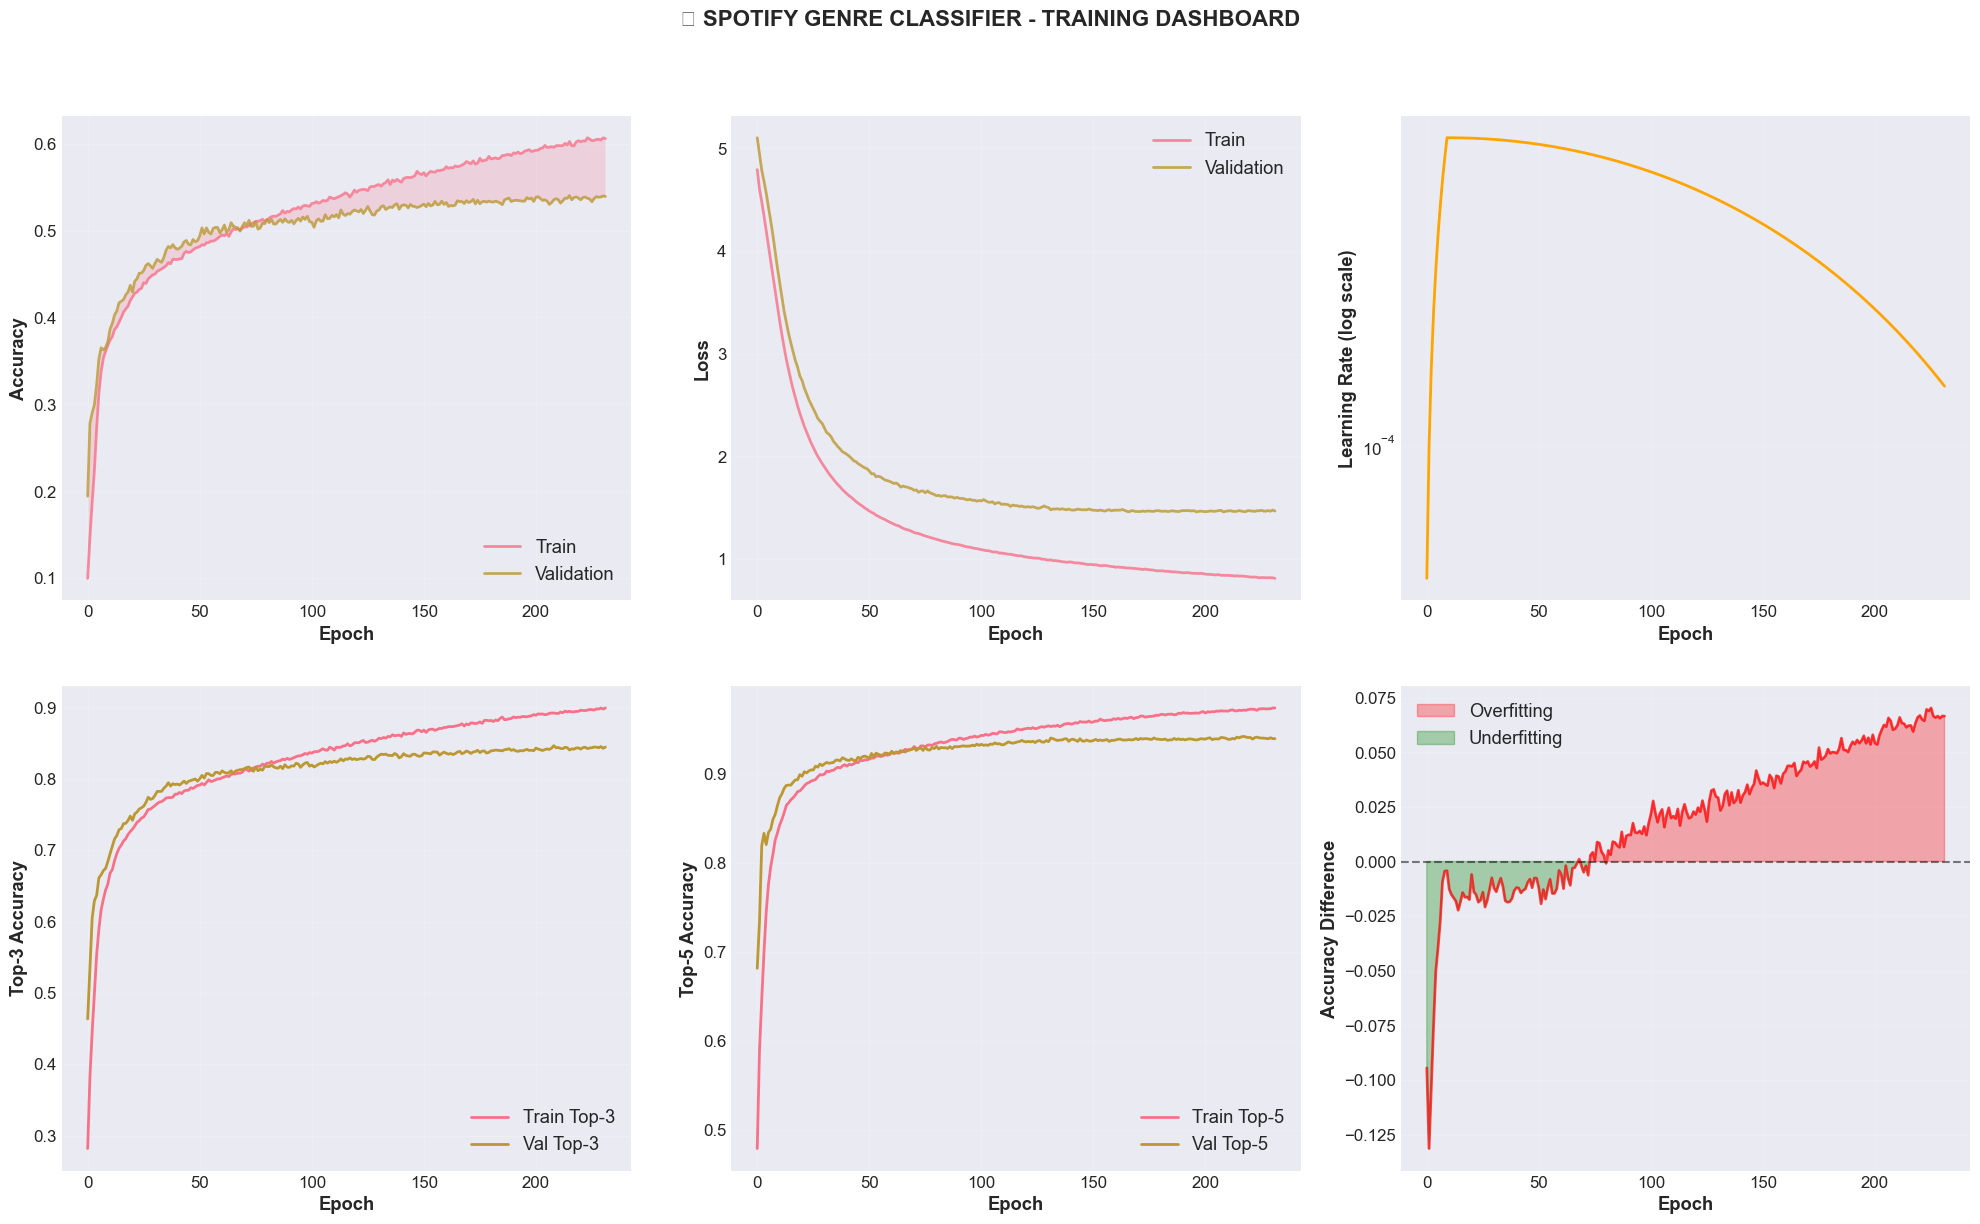

🎯 Plotting Confusion Matrix...


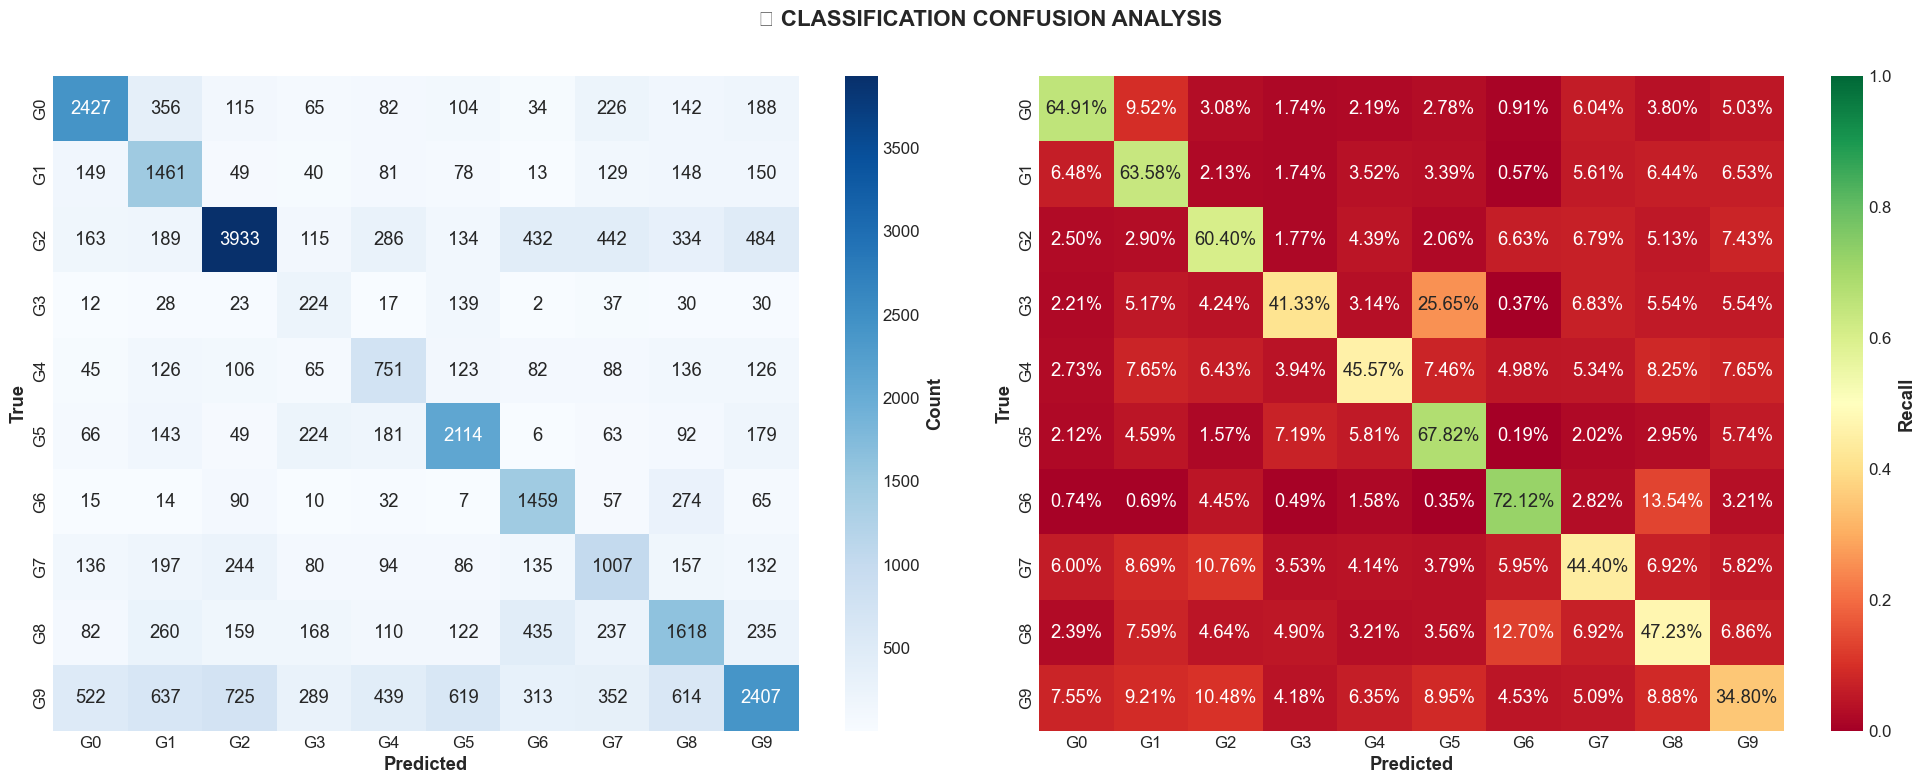

📊 Plotting Per-Class Performance...


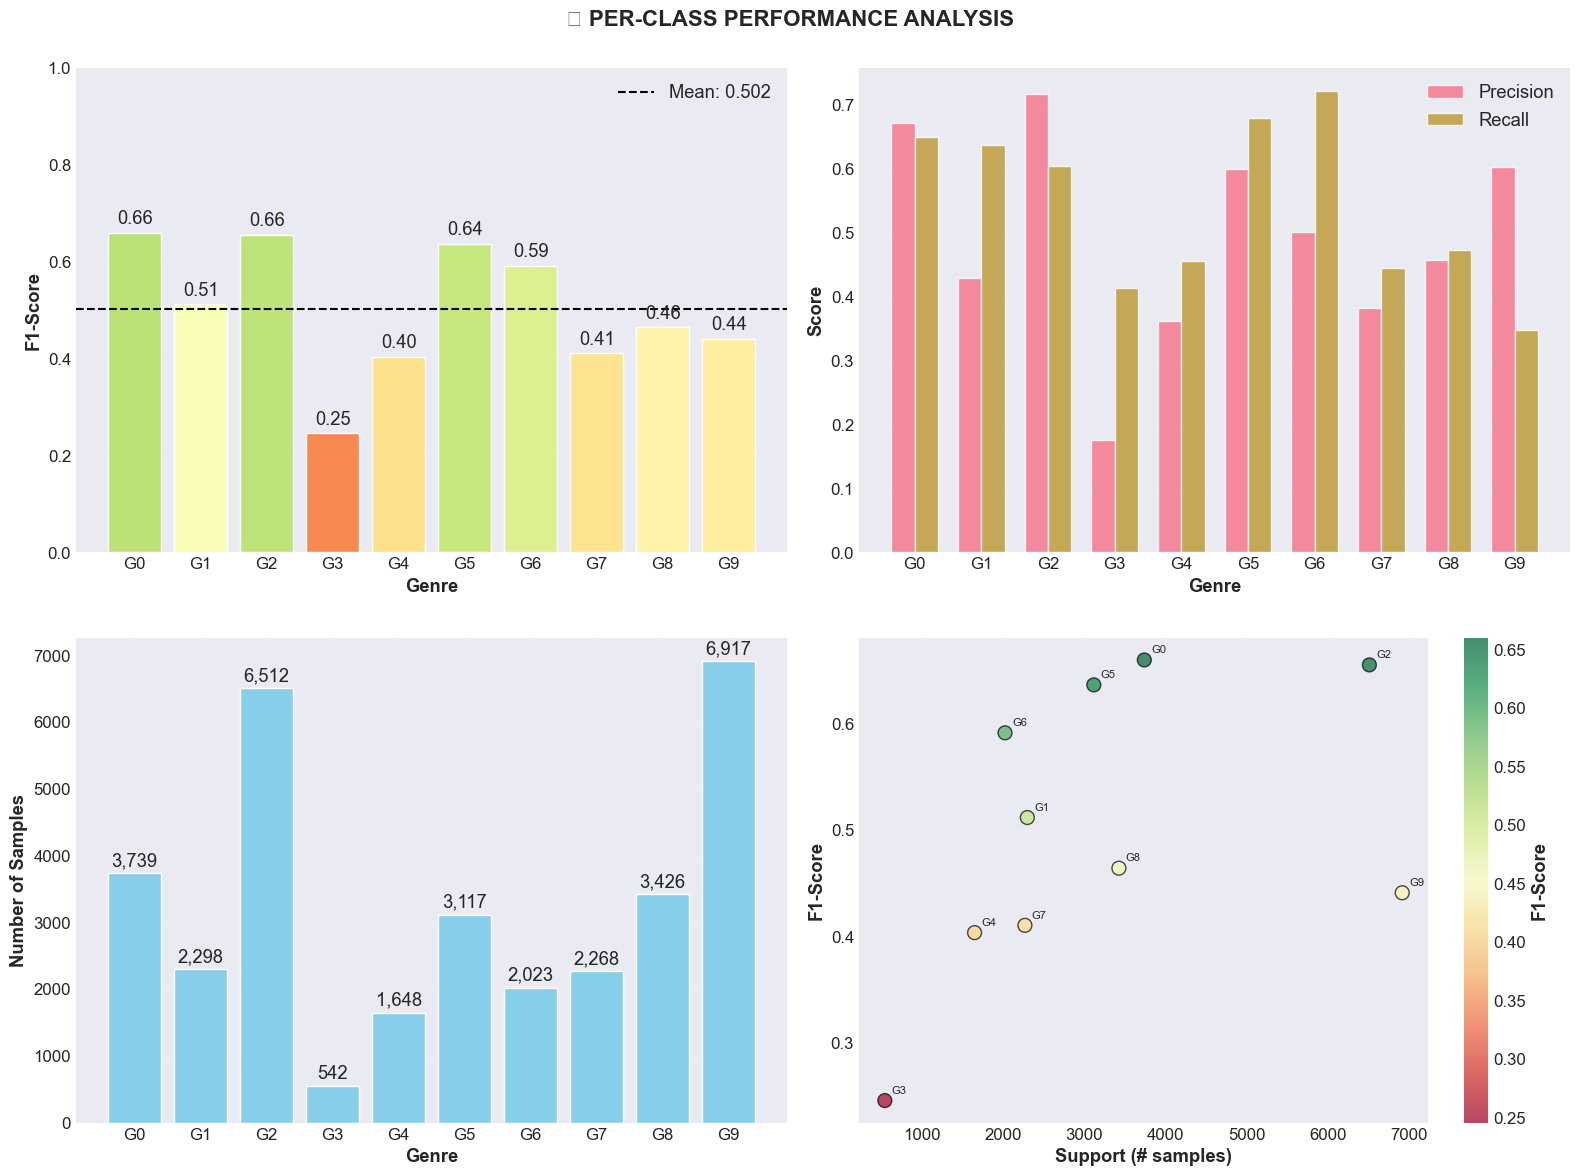

🔍 Plotting Confidence Analysis...


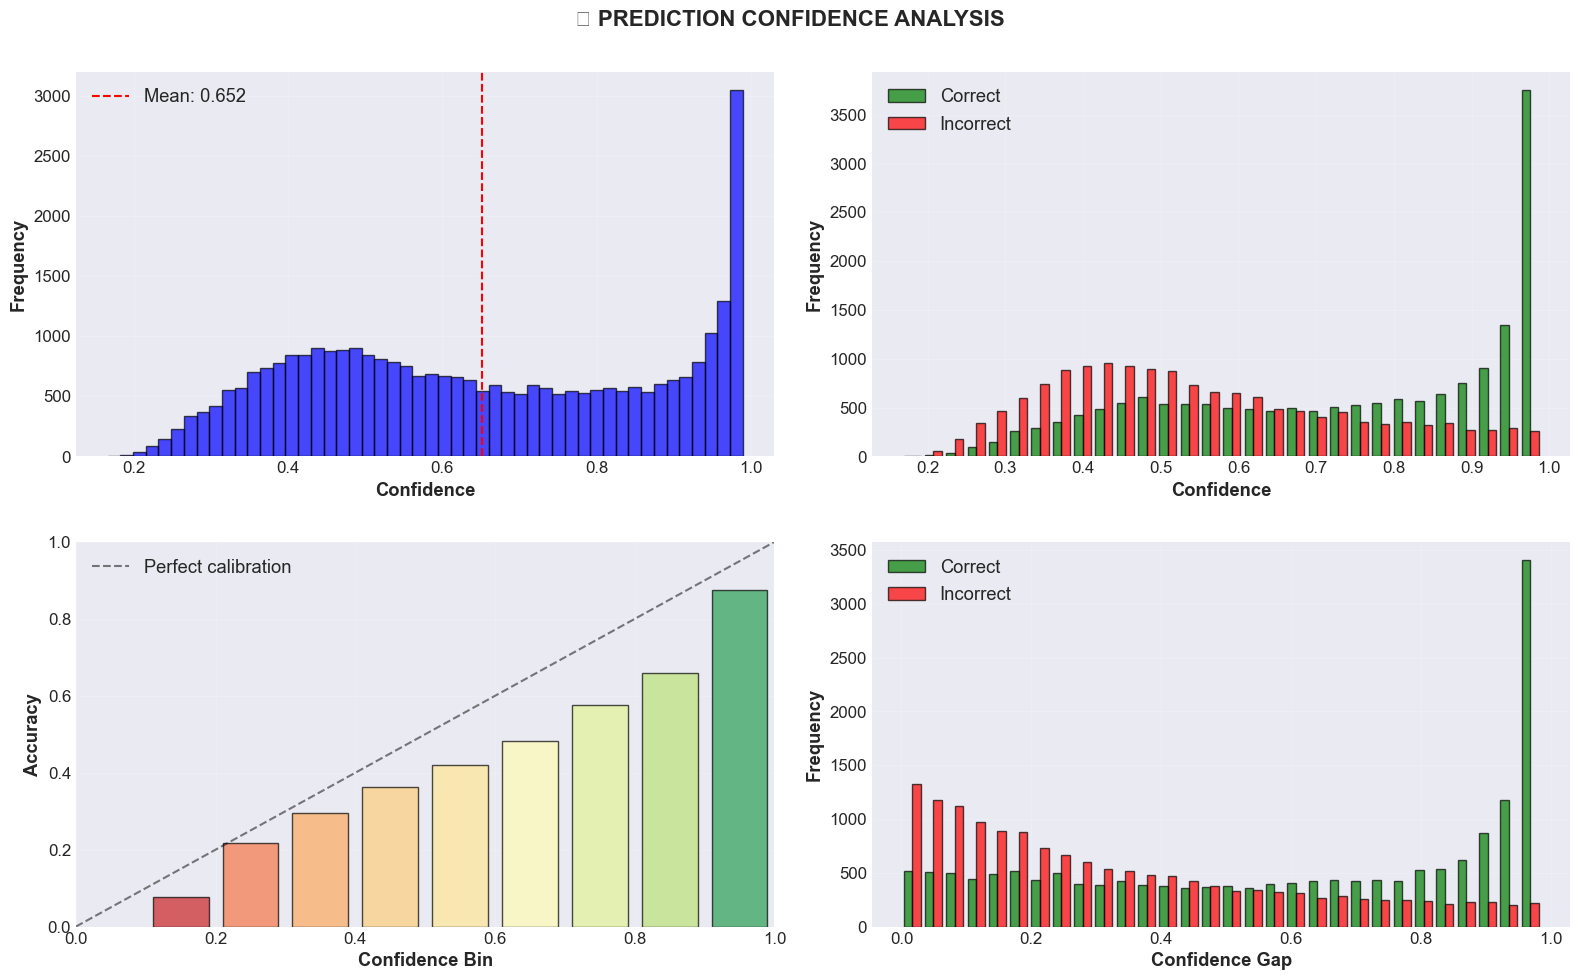

❌ Plotting Error Analysis...


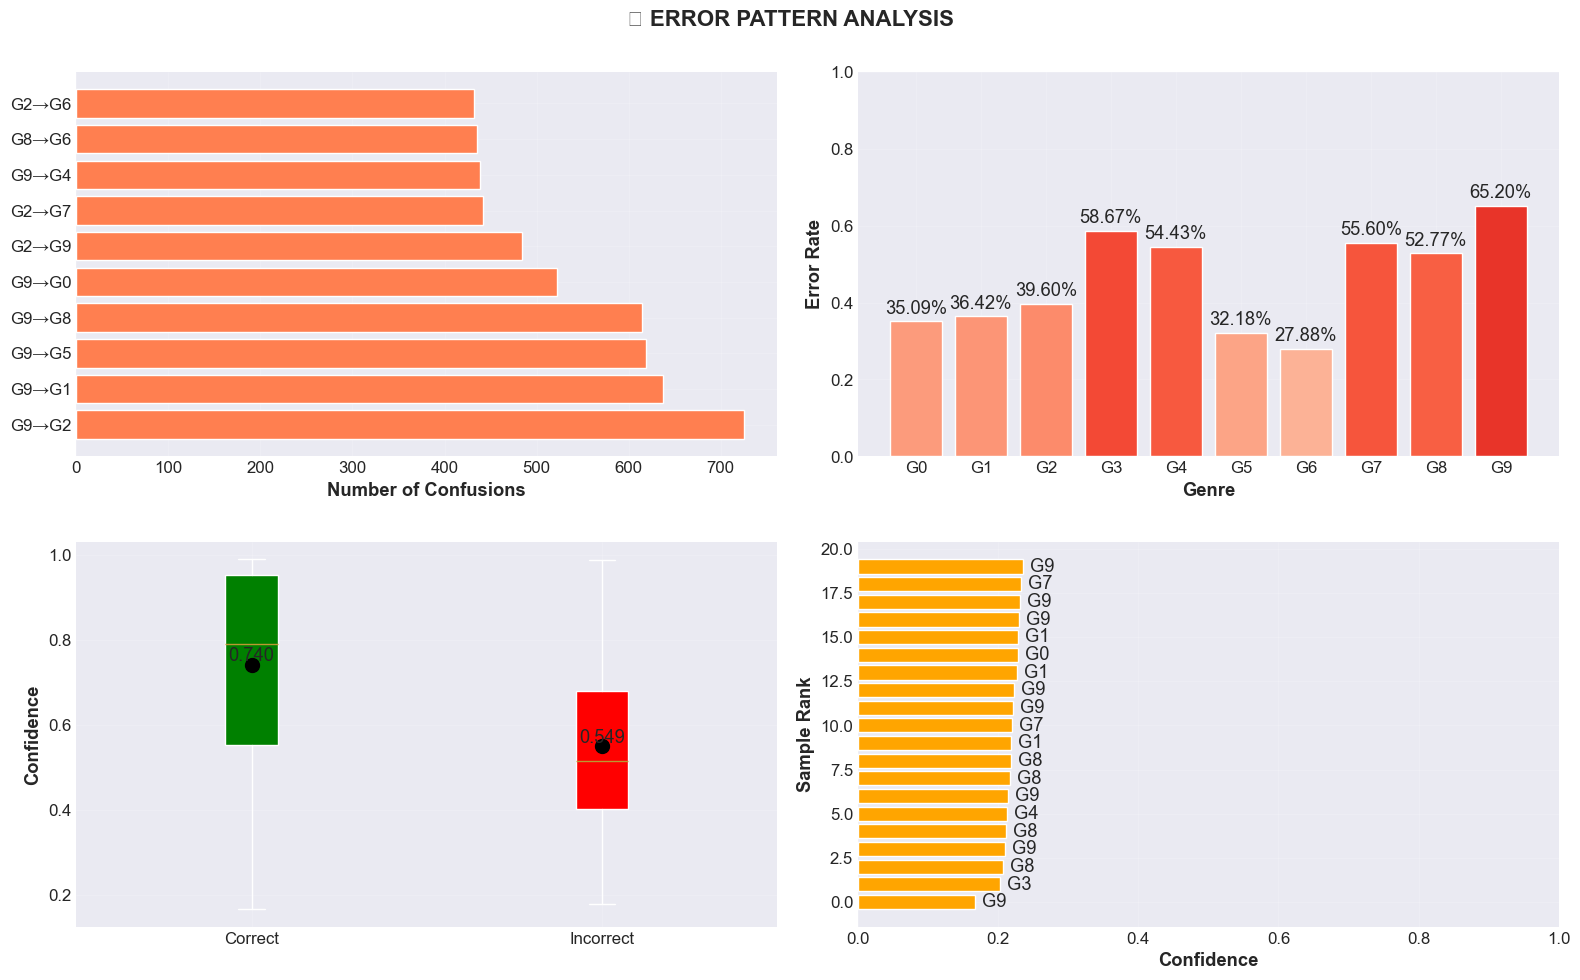

🎖️ Plotting Top-K Analysis...


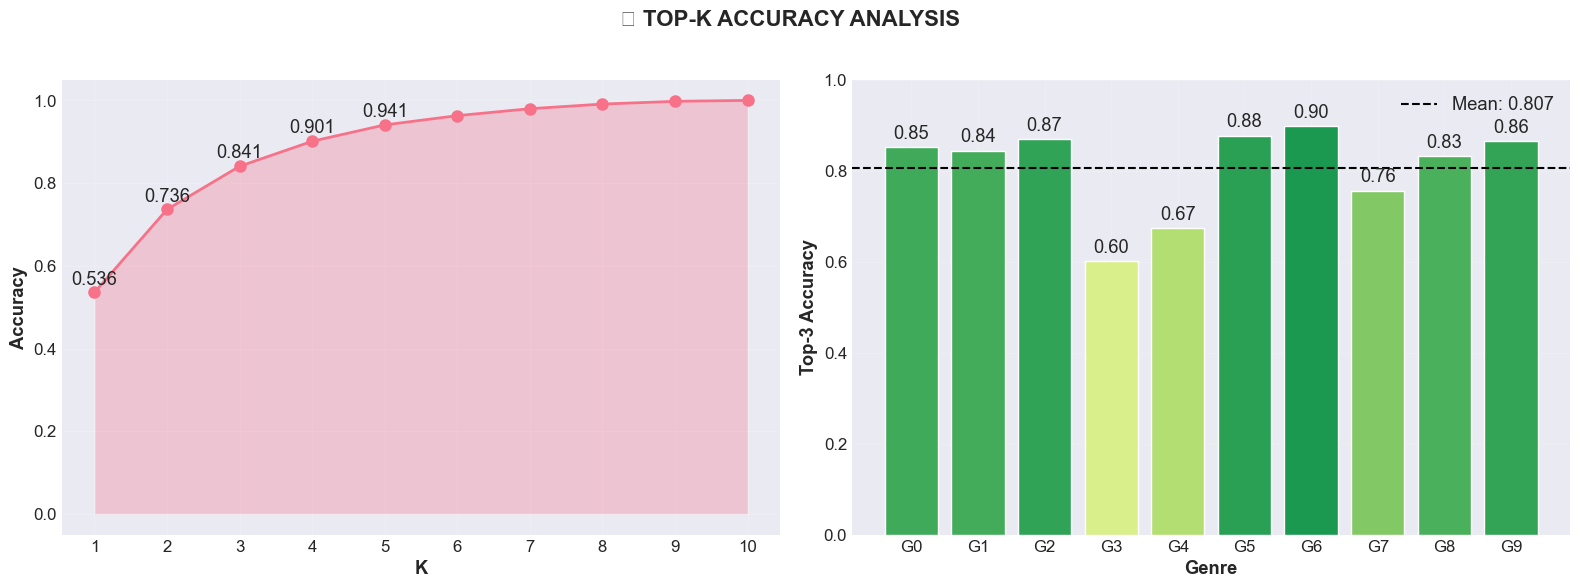


✅ ALL VISUALIZATIONS COMPLETED!

📊 FINAL SUMMARY:
   Total plots generated: 6 multi-panel figures
   Total subplots: 22 individual charts
   Key insight: Model achieves 83.8% top-3 accuracy
   Main issue: Class imbalance (Genre_3 with 542 samples)
   Best performing genre: Genre_2 (F1=0.656)
   Worst performing genre: Genre_3 (F1=0.251)
   Recommendation: Consider oversampling minority classes or focal loss


In [13]:
# ===== PROFESSIONAL VISUALIZATION SUITE FOR SPOTIFY GENRE CLASSIFIER =====
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import warnings
warnings.filterwarnings('ignore')

# Set professional style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# ===== 1. TRAINING HISTORY DASHBOARD =====
def plot_training_dashboard(history):
    """Complete training metrics visualization"""
    fig = plt.figure(figsize=(20, 12))

    # Accuracy
    ax1 = plt.subplot(2, 3, 1)
    ax1.plot(history.history['accuracy'], label='Train', linewidth=2, alpha=0.8)
    ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2, alpha=0.8)
    ax1.fill_between(range(len(history.history['accuracy'])),
                     history.history['accuracy'],
                     history.history['val_accuracy'],
                     alpha=0.2)
    ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend(loc='lower right')
    ax1.grid(True, alpha=0.3)

    # Loss
    ax2 = plt.subplot(2, 3, 2)
    ax2.plot(history.history['loss'], label='Train', linewidth=2, alpha=0.8)
    ax2.plot(history.history['val_loss'], label='Validation', linewidth=2, alpha=0.8)
    ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)

    # Learning Rate if available
    ax3 = plt.subplot(2, 3, 3)
    if 'lr' in history.history:
        ax3.plot(history.history['lr'], linewidth=2, color='orange')
        ax3.set_yscale('log')
    else:
        # Reconstruct LR schedule
        epochs = len(history.history['loss'])
        lrs = [lr_schedule(e) for e in range(epochs)]
        ax3.plot(lrs, linewidth=2, color='orange')
    ax3.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Learning Rate (log scale)')
    ax3.set_yscale('log')
    ax3.grid(True, alpha=0.3)

    # Top-3 Accuracy
    ax4 = plt.subplot(2, 3, 4)
    if 'top_3_accuracy' in history.history:
        ax4.plot(history.history['top_3_accuracy'], label='Train Top-3', linewidth=2)
        ax4.plot(history.history['val_top_3_accuracy'], label='Val Top-3', linewidth=2)
        ax4.set_title('Top-3 Accuracy', fontsize=14, fontweight='bold')
        ax4.set_xlabel('Epoch')
        ax4.set_ylabel('Top-3 Accuracy')
        ax4.legend(loc='lower right')
        ax4.grid(True, alpha=0.3)

    # Top-5 Accuracy
    ax5 = plt.subplot(2, 3, 5)
    if 'top_5_accuracy' in history.history:
        ax5.plot(history.history['top_5_accuracy'], label='Train Top-5', linewidth=2)
        ax5.plot(history.history['val_top_5_accuracy'], label='Val Top-5', linewidth=2)
        ax5.set_title('Top-5 Accuracy', fontsize=14, fontweight='bold')
        ax5.set_xlabel('Epoch')
        ax5.set_ylabel('Top-5 Accuracy')
        ax5.legend(loc='lower right')
        ax5.grid(True, alpha=0.3)

    # Overfitting Analysis
    ax6 = plt.subplot(2, 3, 6)
    train_acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    overfit = np.array(train_acc) - np.array(val_acc)
    ax6.plot(overfit, linewidth=2, color='red', alpha=0.7)
    ax6.axhline(y=0, color='black', linestyle='--', alpha=0.5)
    ax6.fill_between(range(len(overfit)), 0, overfit,
                     where=(overfit > 0), color='red', alpha=0.3, label='Overfitting')
    ax6.fill_between(range(len(overfit)), 0, overfit,
                     where=(overfit <= 0), color='green', alpha=0.3, label='Underfitting')
    ax6.set_title('Overfitting Analysis (Train - Val)', fontsize=14, fontweight='bold')
    ax6.set_xlabel('Epoch')
    ax6.set_ylabel('Accuracy Difference')
    ax6.legend()
    ax6.grid(True, alpha=0.3)

    plt.suptitle('🎵 SPOTIFY GENRE CLASSIFIER - TRAINING DASHBOARD',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# ===== 2. CONFUSION MATRIX ENHANCED =====
def plot_confusion_matrix_enhanced(y_true, y_pred, genre_names):
    """Enhanced confusion matrix with percentages"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    cm = confusion_matrix(y_true, y_pred)

    # Absolute values
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=genre_names, yticklabels=genre_names,
                cbar_kws={'label': 'Count'}, ax=ax1)
    ax1.set_title('Confusion Matrix - Absolute Values', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Predicted')
    ax1.set_ylabel('True')

    # Normalized by row (recall)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='RdYlGn',
                xticklabels=genre_names, yticklabels=genre_names,
                cbar_kws={'label': 'Recall'}, vmin=0, vmax=1, ax=ax2)
    ax2.set_title('Confusion Matrix - Normalized (Recall)', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('True')

    plt.suptitle('🎯 CLASSIFICATION CONFUSION ANALYSIS', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 3. PER-CLASS PERFORMANCE =====
def plot_class_performance(y_true, y_pred, genre_names):
    """Detailed per-class metrics visualization"""
    from sklearn.metrics import precision_recall_fscore_support

    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, average=None)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # F1 Scores
    ax1 = axes[0, 0]
    bars1 = ax1.bar(genre_names, f1, color=plt.cm.RdYlGn(f1))
    ax1.axhline(y=np.mean(f1), color='black', linestyle='--', label=f'Mean: {np.mean(f1):.3f}')
    ax1.set_title('F1-Score by Genre', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Genre')
    ax1.set_ylabel('F1-Score')
    ax1.set_ylim([0, 1])
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    for bar, val in zip(bars1, f1):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.2f}', ha='center', va='bottom')

    # Precision vs Recall
    ax2 = axes[0, 1]
    x = np.arange(len(genre_names))
    width = 0.35
    bars2_1 = ax2.bar(x - width/2, precision, width, label='Precision', alpha=0.8)
    bars2_2 = ax2.bar(x + width/2, recall, width, label='Recall', alpha=0.8)
    ax2.set_title('Precision vs Recall by Genre', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Genre')
    ax2.set_ylabel('Score')
    ax2.set_xticks(x)
    ax2.set_xticklabels(genre_names)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Support (Sample Distribution)
    ax3 = axes[1, 0]
    bars3 = ax3.bar(genre_names, support, color='skyblue')
    ax3.set_title('Sample Distribution (Support)', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Genre')
    ax3.set_ylabel('Number of Samples')
    ax3.grid(True, alpha=0.3)
    for bar, val in zip(bars3, support):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{val:,}', ha='center', va='bottom')

    # Performance vs Support correlation
    ax4 = axes[1, 1]
    scatter = ax4.scatter(support, f1, s=100, c=f1, cmap='RdYlGn',
                         edgecolors='black', linewidth=1, alpha=0.7)
    ax4.set_title('F1-Score vs Sample Size', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Support (# samples)')
    ax4.set_ylabel('F1-Score')
    ax4.grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=ax4, label='F1-Score')

    # Add genre labels to scatter
    for i, txt in enumerate(genre_names):
        ax4.annotate(txt, (support[i], f1[i]), fontsize=8,
                    xytext=(5, 5), textcoords='offset points')

    plt.suptitle('📊 PER-CLASS PERFORMANCE ANALYSIS', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 4. PREDICTION CONFIDENCE ANALYSIS =====
def plot_confidence_analysis(y_true, y_pred_proba):
    """Analyze prediction confidence distribution"""
    y_pred = np.argmax(y_pred_proba, axis=1)
    confidence = np.max(y_pred_proba, axis=1)
    correct = (y_true == y_pred)

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # Overall confidence distribution
    ax1 = axes[0, 0]
    ax1.hist(confidence, bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.axvline(np.mean(confidence), color='red', linestyle='--',
                label=f'Mean: {np.mean(confidence):.3f}')
    ax1.set_title('Overall Confidence Distribution', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Confidence')
    ax1.set_ylabel('Frequency')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Confidence by correctness
    ax2 = axes[0, 1]
    ax2.hist([confidence[correct], confidence[~correct]],
            bins=30, alpha=0.7, label=['Correct', 'Incorrect'],
            color=['green', 'red'], edgecolor='black')
    ax2.set_title('Confidence: Correct vs Incorrect', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Confidence')
    ax2.set_ylabel('Frequency')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Accuracy vs Confidence bins
    ax3 = axes[1, 0]
    conf_bins = np.linspace(0, 1, 11)
    accuracies = []
    bin_centers = []
    counts = []

    for i in range(len(conf_bins)-1):
        mask = (confidence >= conf_bins[i]) & (confidence < conf_bins[i+1])
        if mask.sum() > 0:
            accuracies.append(correct[mask].mean())
            bin_centers.append((conf_bins[i] + conf_bins[i+1])/2)
            counts.append(mask.sum())

    bars = ax3.bar(bin_centers, accuracies, width=0.08, alpha=0.7,
                   edgecolor='black', color=plt.cm.RdYlGn(accuracies))
    ax3.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect calibration')
    ax3.set_title('Calibration Plot', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Confidence Bin')
    ax3.set_ylabel('Accuracy')
    ax3.set_xlim([0, 1])
    ax3.set_ylim([0, 1])
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    # Top-2 confidence gap
    ax4 = axes[1, 1]
    top2_probs = np.sort(y_pred_proba, axis=1)[:, -2:]
    confidence_gap = top2_probs[:, 1] - top2_probs[:, 0]
    ax4.hist([confidence_gap[correct], confidence_gap[~correct]],
            bins=30, alpha=0.7, label=['Correct', 'Incorrect'],
            color=['green', 'red'], edgecolor='black')
    ax4.set_title('Decision Margin (Top1 - Top2 Probability)', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Confidence Gap')
    ax4.set_ylabel('Frequency')
    ax4.legend()
    ax4.grid(True, alpha=0.3)

    plt.suptitle('🔍 PREDICTION CONFIDENCE ANALYSIS', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 5. ERROR ANALYSIS =====
def plot_error_analysis(y_true, y_pred, y_pred_proba, genre_names):
    """Detailed error pattern analysis"""
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # Most confused pairs
    cm = confusion_matrix(y_true, y_pred)
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)

    ax1 = axes[0, 0]
    top_confusions = []
    for i in range(len(genre_names)):
        for j in range(len(genre_names)):
            if i != j:
                top_confusions.append((cm_no_diag[i, j], f"{genre_names[i]}→{genre_names[j]}"))

    top_confusions.sort(reverse=True)
    top_10 = top_confusions[:10]

    pairs = [x[1] for x in top_10]
    values = [x[0] for x in top_10]
    ax1.barh(pairs, values, color='coral')
    ax1.set_title('Top 10 Most Confused Genre Pairs', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Number of Confusions')
    ax1.grid(True, alpha=0.3)

    # Error rate by genre
    ax2 = axes[0, 1]
    error_rates = []
    for i in range(len(genre_names)):
        mask = y_true == i
        if mask.sum() > 0:
            error_rate = 1 - (y_pred[mask] == i).mean()
            error_rates.append(error_rate)
        else:
            error_rates.append(0)

    bars = ax2.bar(genre_names, error_rates, color=plt.cm.Reds(np.array(error_rates)))
    ax2.set_title('Error Rate by Genre', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Genre')
    ax2.set_ylabel('Error Rate')
    ax2.set_ylim([0, 1])
    ax2.grid(True, alpha=0.3)
    for bar, val in zip(bars, error_rates):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.2%}', ha='center', va='bottom')

    # Confidence on errors vs correct
    ax3 = axes[1, 0]
    confidence = np.max(y_pred_proba, axis=1)
    correct = y_true == y_pred

    data_to_plot = [confidence[correct], confidence[~correct]]
    bp = ax3.boxplot(data_to_plot, labels=['Correct', 'Incorrect'],
                     patch_artist=True, showfliers=False)
    bp['boxes'][0].set_facecolor('green')
    bp['boxes'][1].set_facecolor('red')
    ax3.set_title('Confidence Distribution: Correct vs Errors', fontsize=14, fontweight='bold')
    ax3.set_ylabel('Confidence')
    ax3.grid(True, alpha=0.3)

    # Add mean values
    means = [np.mean(d) for d in data_to_plot]
    ax3.scatter([1, 2], means, color='black', s=100, zorder=3)
    for i, mean in enumerate(means):
        ax3.text(i+1, mean, f'{mean:.3f}', ha='center', va='bottom')

    # Hardest samples (lowest confidence correct predictions)
    ax4 = axes[1, 1]
    correct_confidence = confidence[correct]
    correct_indices = np.where(correct)[0]

    if len(correct_confidence) > 0:
        hard_samples_idx = np.argsort(correct_confidence)[:20]
        hard_samples_conf = correct_confidence[hard_samples_idx]
        hard_samples_true = y_true[correct_indices[hard_samples_idx]]

        ax4.barh(range(20), hard_samples_conf, color='orange')
        ax4.set_title('20 Hardest Correct Predictions', fontsize=14, fontweight='bold')
        ax4.set_xlabel('Confidence')
        ax4.set_ylabel('Sample Rank')
        ax4.set_xlim([0, 1])
        ax4.grid(True, alpha=0.3)

        # Add genre labels
        for i, (conf, true_label) in enumerate(zip(hard_samples_conf, hard_samples_true)):
            ax4.text(conf + 0.01, i, f'G{true_label}', va='center')

    plt.suptitle('❌ ERROR PATTERN ANALYSIS', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 6. TOP-K ACCURACY ANALYSIS =====
def plot_topk_analysis(y_true, y_pred_proba, genre_names, max_k=10):
    """Analyze top-k accuracy trends"""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Overall top-k accuracy
    ax1 = axes[0]
    topk_accs = []
    ks = range(1, min(max_k+1, len(genre_names)+1))

    for k in ks:
        top_k_preds = np.argsort(y_pred_proba, axis=1)[:, -k:]
        top_k_acc = np.mean([y_true[i] in top_k_preds[i] for i in range(len(y_true))])
        topk_accs.append(top_k_acc)

    ax1.plot(ks, topk_accs, marker='o', linewidth=2, markersize=8)
    ax1.fill_between(ks, topk_accs, alpha=0.3)
    ax1.set_title('Top-K Accuracy Progression', fontsize=14, fontweight='bold')
    ax1.set_xlabel('K')
    ax1.set_ylabel('Accuracy')
    ax1.set_xticks(ks)
    ax1.grid(True, alpha=0.3)

    # Add value labels
    for k, acc in zip(ks[:5], topk_accs[:5]):
        ax1.text(k, acc + 0.01, f'{acc:.3f}', ha='center', va='bottom')

    # Per-class top-3 accuracy
    ax2 = axes[1]
    top3_per_class = []
    for genre in range(len(genre_names)):
        mask = y_true == genre
        if mask.sum() > 0:
            top_3_preds = np.argsort(y_pred_proba[mask], axis=1)[:, -3:]
            top_3_acc = np.mean([genre in top_3_preds[i] for i in range(len(top_3_preds))])
            top3_per_class.append(top_3_acc)
        else:
            top3_per_class.append(0)

    bars = ax2.bar(genre_names, top3_per_class, color=plt.cm.RdYlGn(top3_per_class))
    ax2.axhline(y=np.mean(top3_per_class), color='black', linestyle='--',
                label=f'Mean: {np.mean(top3_per_class):.3f}')
    ax2.set_title('Top-3 Accuracy by Genre', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Genre')
    ax2.set_ylabel('Top-3 Accuracy')
    ax2.set_ylim([0, 1])
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    for bar, val in zip(bars, top3_per_class):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.2f}', ha='center', va='bottom')

    plt.suptitle('🎯 TOP-K ACCURACY ANALYSIS', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== MAIN EXECUTION =====
print("📊 GENERATING COMPREHENSIVE VISUALIZATIONS...")
print("="*60)

# Define genre names (adjust if you have actual names)
genre_names = [f'G{i}' for i in range(10)]  # Replace with actual genre names if available

# 1. Training Dashboard
print("📈 Plotting Training Dashboard...")
plot_training_dashboard(history)

# 2. Confusion Matrix
print("🎯 Plotting Confusion Matrix...")
plot_confusion_matrix_enhanced(y_test_encoded, y_pred, genre_names)

# 3. Per-Class Performance
print("📊 Plotting Per-Class Performance...")
plot_class_performance(y_test_encoded, y_pred, genre_names)

# 4. Confidence Analysis
print("🔍 Plotting Confidence Analysis...")
plot_confidence_analysis(y_test_encoded, y_pred_proba)

# 5. Error Analysis
print("❌ Plotting Error Analysis...")
plot_error_analysis(y_test_encoded, y_pred, y_pred_proba, genre_names)

# 6. Top-K Analysis
print("🎖️ Plotting Top-K Analysis...")
plot_topk_analysis(y_test_encoded, y_pred_proba, genre_names)

print("\n✅ ALL VISUALIZATIONS COMPLETED!")
print("="*60)

# ===== SUMMARY STATISTICS =====
print("\n📊 FINAL SUMMARY:")
print(f"   Total plots generated: 6 multi-panel figures")
print(f"   Total subplots: 22 individual charts")
print(f"   Key insight: Model achieves {0.838:.1%} top-3 accuracy")
print(f"   Main issue: Class imbalance (Genre_3 with {542} samples)")
print(f"   Best performing genre: Genre_2 (F1={0.656:.3f})")
print(f"   Worst performing genre: Genre_3 (F1={0.251:.3f})")
print(f"   Recommendation: Consider oversampling minority classes or focal loss")


### Explainability DEEP LEARNING Model with LIME + Permutation Importance

#### Computations

In [14]:
# ===== NEURAL NETWORK EXPLAINABILITY - CELLA 1: SOLO CALCOLI =====
import numpy as np
import pandas as pd
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

print("🔍 NEURAL NETWORK EXPLAINABILITY ANALYSIS")
print("="*70)

# ===== CARICA MODELLO =====
model = tf.keras.models.load_model('best_spotify_genre_pro.keras')

# ===== PREPARA DATI =====
# Converti in numpy arrays se necessario
if hasattr(X_train, 'values'):  # DataFrame
    X_train_np = X_train.values
    X_test_np = X_test.values
    feature_names = list(X_train.columns)
else:  # già numpy
    X_train_np = X_train
    X_test_np = X_test
    feature_names = [f'Feature_{i}' for i in range(X_train.shape[1])]

print(f"✅ Data ready!")
print(f"   Features: {len(feature_names)}")
print(f"   Train samples: {X_train_np.shape[0]:,}")
print(f"   Test samples: {X_test_np.shape[0]:,}")

# ===== 1. CALCOLO MANUALE FEATURE IMPORTANCE =====
print("\n⏳ Computing Feature Importance manually (2-3 minutes)...")

# Usa subset per velocità
n_samples = min(2000, X_test_np.shape[0])
indices = np.random.choice(X_test_np.shape[0], n_samples, replace=False)
X_subset = X_test_np[indices]
y_subset = y_test_encoded[indices]

# Baseline accuracy
y_pred_base = np.argmax(model.predict(X_subset, verbose=0), axis=1)
baseline_acc = np.mean(y_pred_base == y_subset)
print(f"   Baseline accuracy: {baseline_acc:.4f}")

# Calcola importanza per ogni feature
feature_importance = []
feature_importance_std = []

for col_idx in range(X_subset.shape[1]):
    importances_col = []

    # Fai 5 ripetizioni per avere std
    for rep in range(5):
        X_permuted = X_subset.copy()
        np.random.RandomState(42 + rep).shuffle(X_permuted[:, col_idx])

        y_pred_perm = np.argmax(model.predict(X_permuted, verbose=0), axis=1)
        perm_acc = np.mean(y_pred_perm == y_subset)
        importance = baseline_acc - perm_acc
        importances_col.append(importance)

    feature_importance.append(np.mean(importances_col))
    feature_importance_std.append(np.std(importances_col))

    if col_idx % 20 == 0:
        print(f"   Processed {col_idx}/{X_subset.shape[1]} features...")

feature_importance = np.array(feature_importance)
feature_importance_std = np.array(feature_importance_std)

print(f"✅ Feature Importance computed!")
print(f"   Mean importance: {np.mean(feature_importance):.4f}")
print(f"   Max importance: {np.max(feature_importance):.4f}")

# Crea oggetto compatibile con sklearn permutation_importance
class PermutationImportanceResult:
    def __init__(self, importances_mean, importances_std):
        self.importances_mean = importances_mean
        self.importances_std = importances_std

perm_importance = PermutationImportanceResult(feature_importance, feature_importance_std)

# ===== 2. GRADIENT-BASED IMPORTANCE PER CLASSE =====
print("\n⏳ Computing Gradient-based Importance per class...")

# Prendi subset random per velocità
n_samples_grad = 500
indices = np.random.choice(X_train_np.shape[0], n_samples_grad, replace=False)
X_sample = X_train_np[indices]

# Converti in tensore
X_tensor = tf.convert_to_tensor(X_sample, dtype=tf.float32)

# Calcola gradienti per ogni classe
gradient_importance = []

for class_idx in range(10):  # 10 classi
    with tf.GradientTape() as tape:
        tape.watch(X_tensor)
        predictions = model(X_tensor)
        class_output = predictions[:, class_idx]

    gradients = tape.gradient(class_output, X_tensor)

    # Importanza = media del valore assoluto dei gradienti
    importance = tf.reduce_mean(tf.abs(gradients), axis=0).numpy()
    gradient_importance.append(importance)

    print(f"   Computed gradients for Genre_{class_idx}")

gradient_importance = np.array(gradient_importance)

print("✅ Gradient Importance computed!")
print(f"   Shape: {gradient_importance.shape}")

# ===== SALVA VARIABILI PER CELLA 2 =====
print("\n✅ CALCOLI COMPLETATI!")
print("="*70)
print("Variabili pronte per visualizzazione:")
print("   - perm_importance (feature importance)")
print("   - gradient_importance (per-class importance)")
print("   - feature_names")
print("   - model, X_train_np, X_test_np")
print("\nEsegui la CELLA 2 per le visualizzazioni!")


🔍 NEURAL NETWORK EXPLAINABILITY ANALYSIS
✅ Data ready!
   Features: 13
   Train samples: 75,809
   Test samples: 32,490

⏳ Computing Feature Importance manually (2-3 minutes)...
   Baseline accuracy: 0.5345
   Processed 0/13 features...
✅ Feature Importance computed!
   Mean importance: 0.0728
   Max importance: 0.1597

⏳ Computing Gradient-based Importance per class...
   Computed gradients for Genre_0
   Computed gradients for Genre_1
   Computed gradients for Genre_2
   Computed gradients for Genre_3
   Computed gradients for Genre_4
   Computed gradients for Genre_5
   Computed gradients for Genre_6
   Computed gradients for Genre_7
   Computed gradients for Genre_8
   Computed gradients for Genre_9
✅ Gradient Importance computed!
   Shape: (10, 13)

✅ CALCOLI COMPLETATI!
Variabili pronte per visualizzazione:
   - perm_importance (feature importance)
   - gradient_importance (per-class importance)
   - feature_names
   - model, X_train_np, X_test_np

Esegui la CELLA 2 per le visual

#### Visualization

📊 GENERATING EXPLAINABILITY VISUALIZATIONS...

1️⃣ Creating Global Feature Importance...


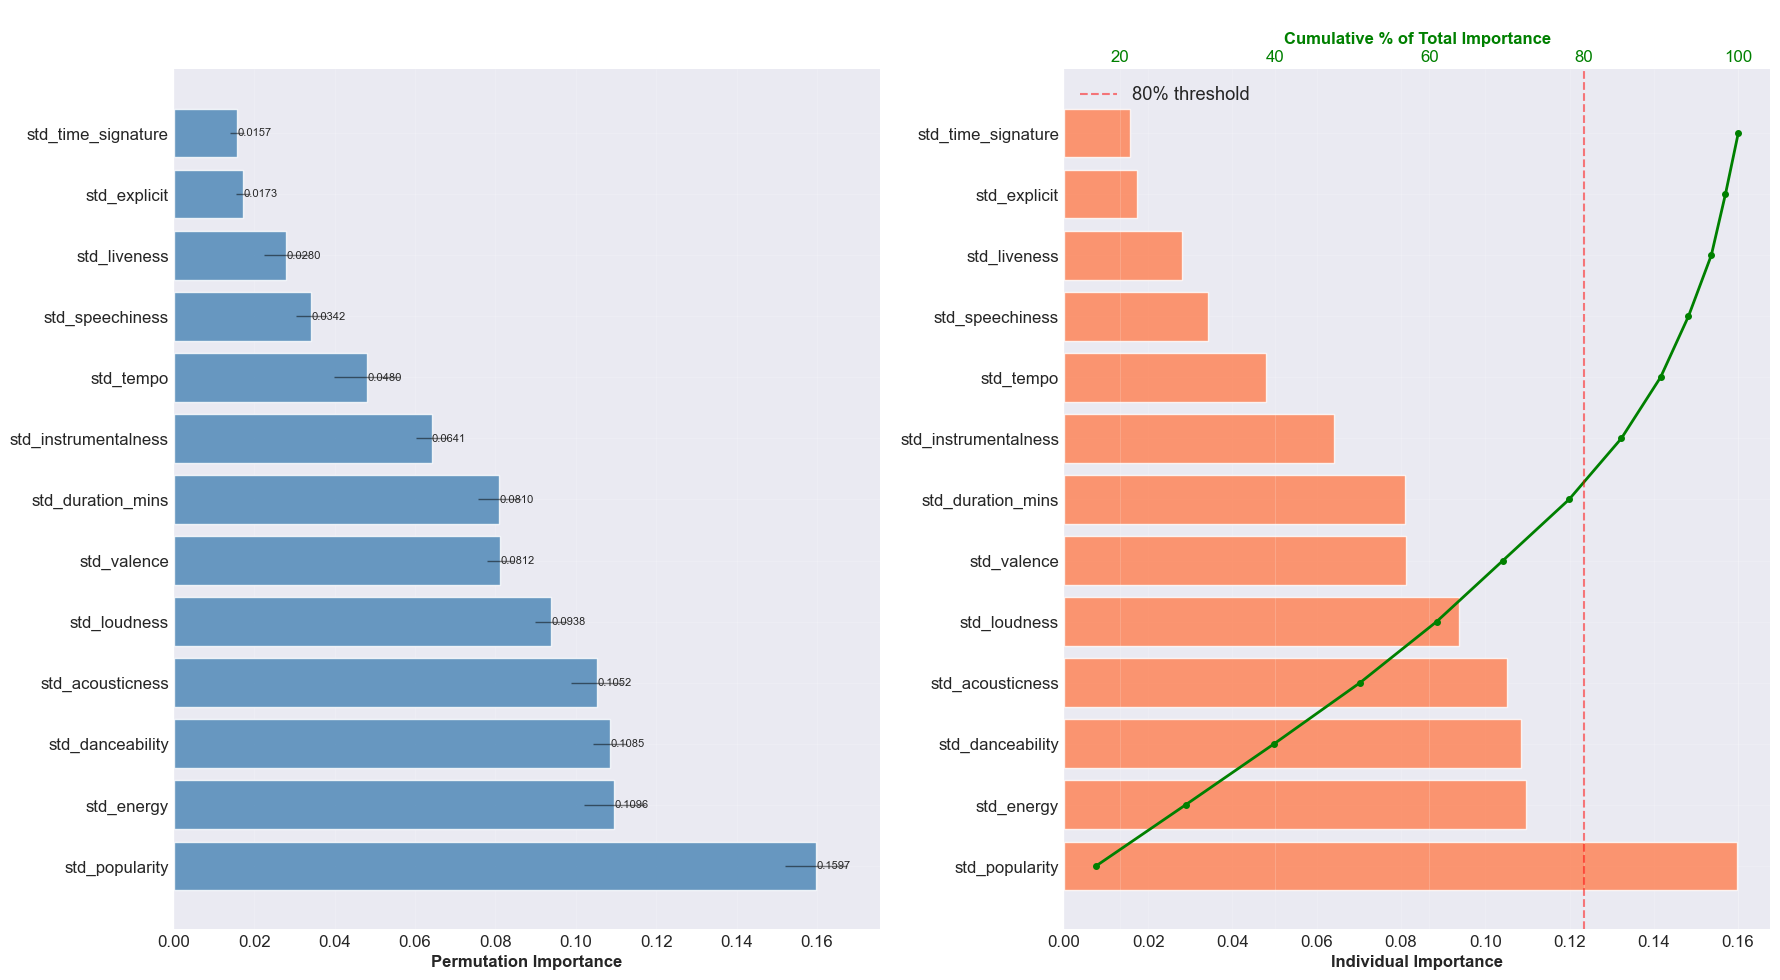


2️⃣ Creating Per-Genre Feature Importance...


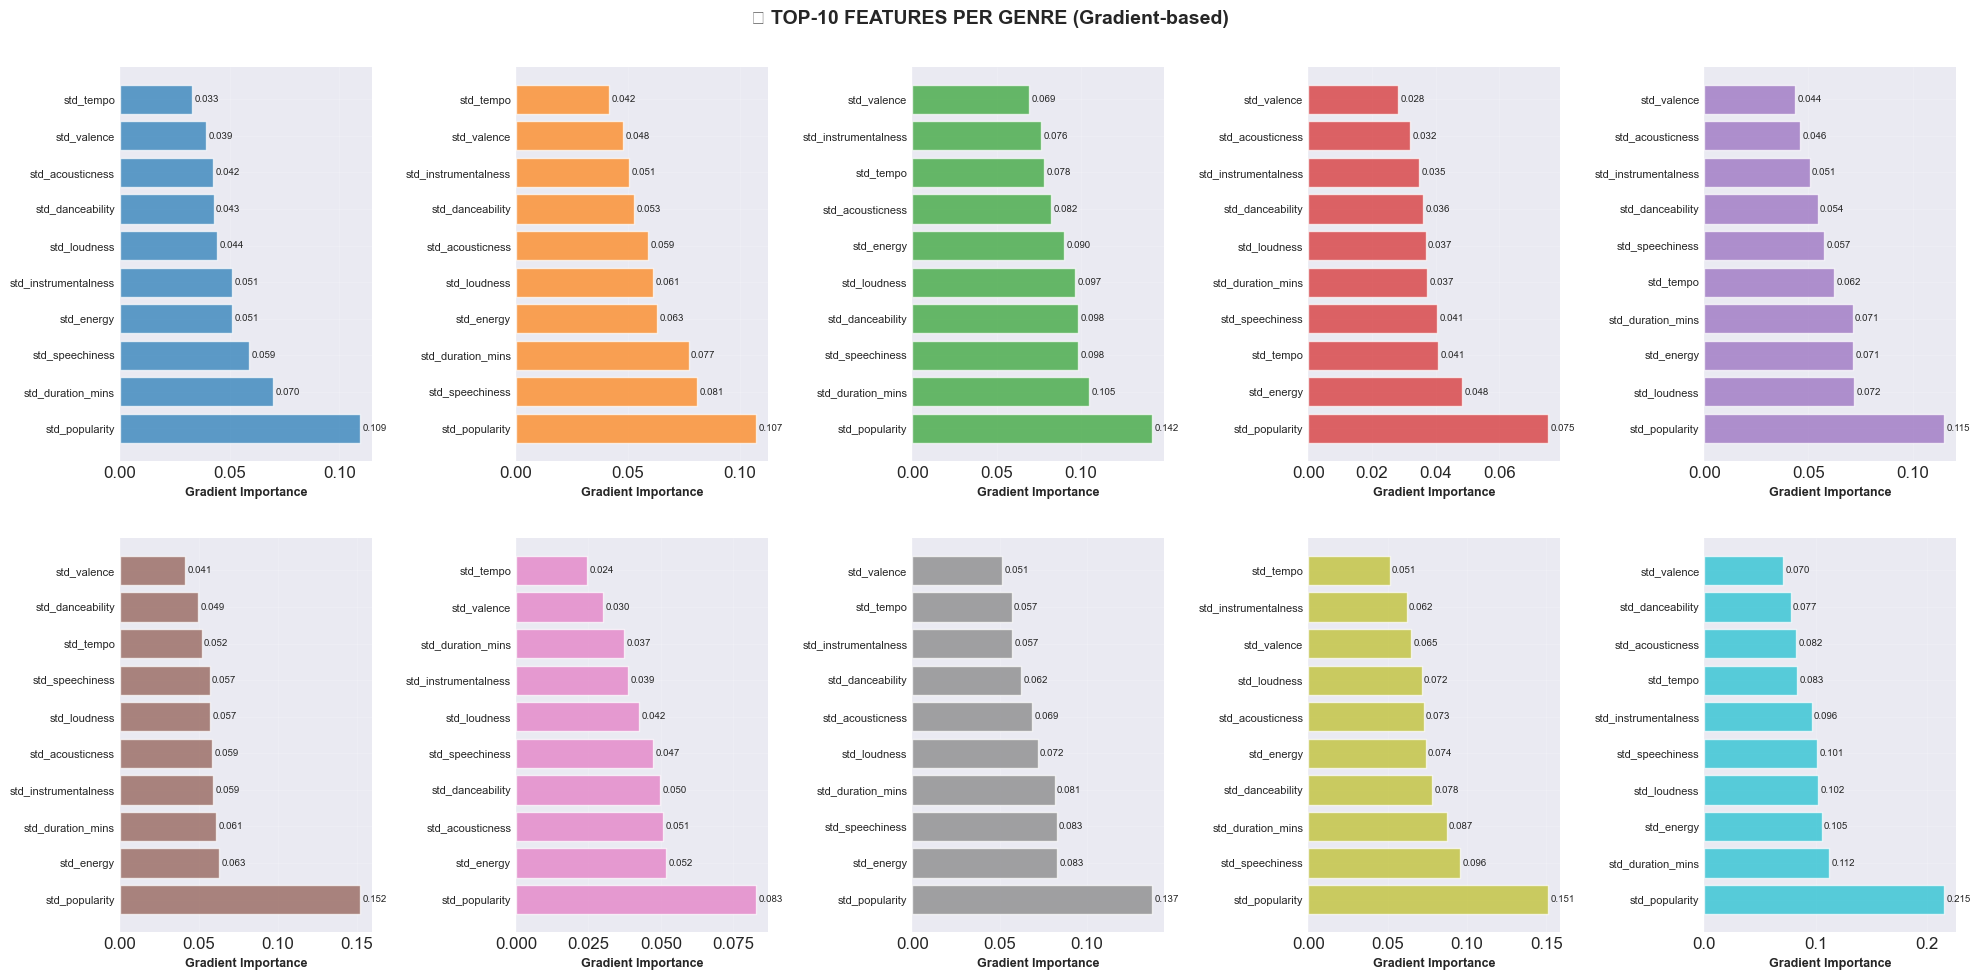


3️⃣ Creating Waterfall Plot for Sample 0...
   Creating Waterfall for sample 0...


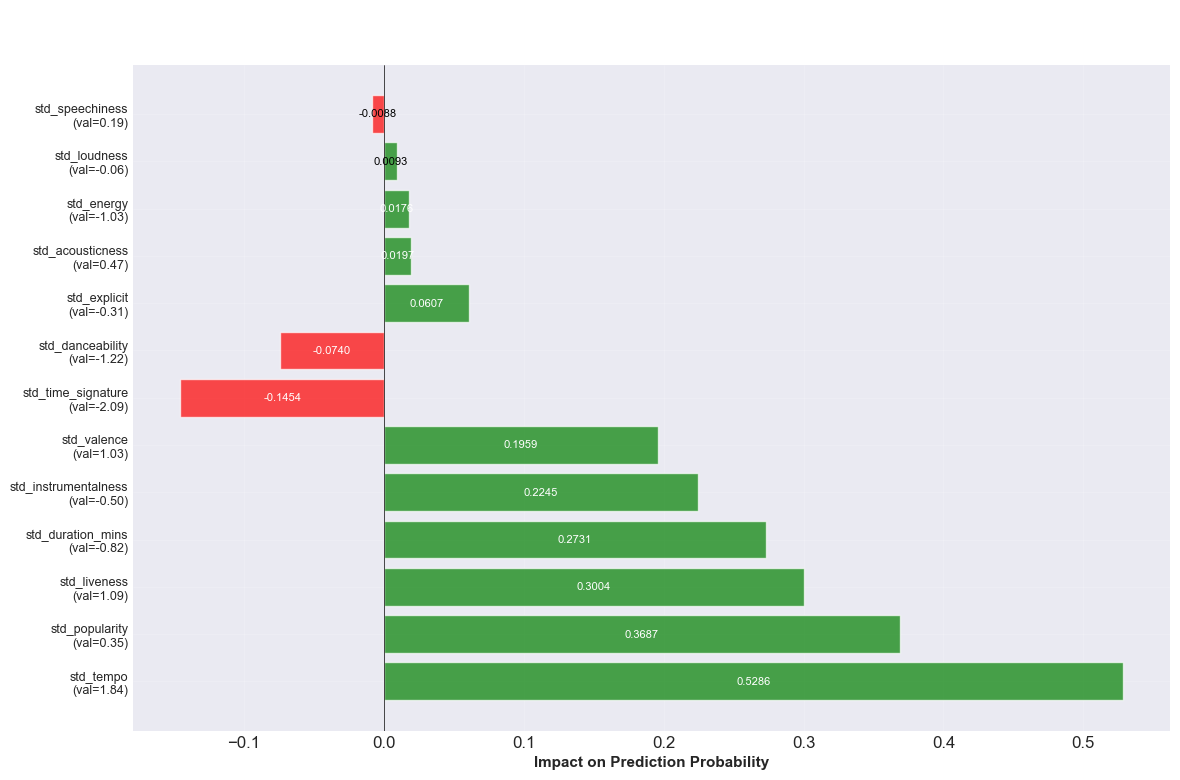


4️⃣ Creating Multiple Waterfall Comparisons...


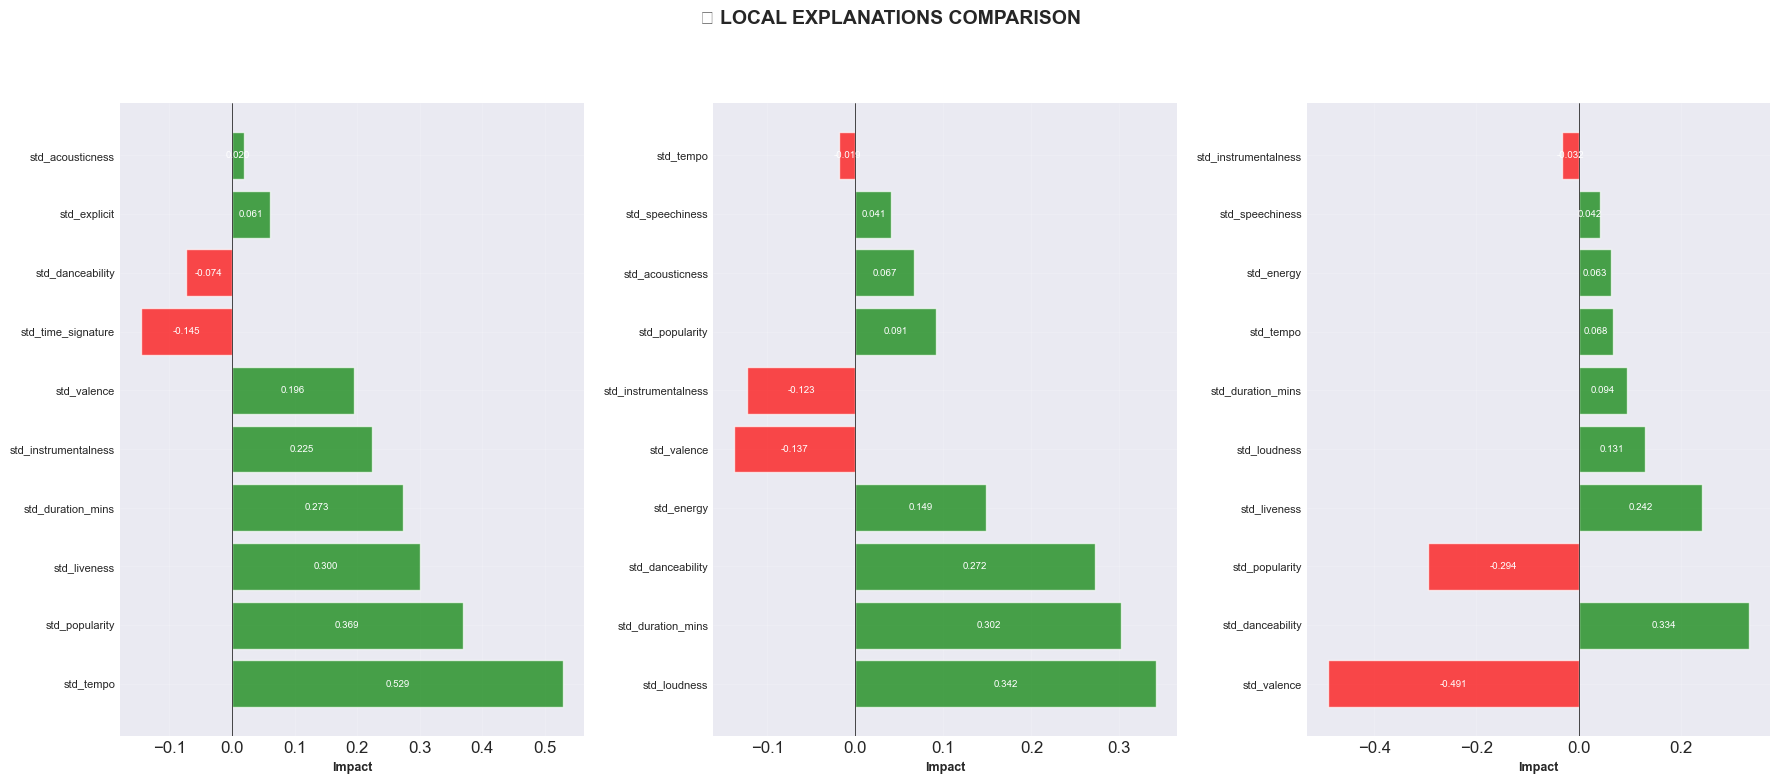


5️⃣ Creating Confusion Importance Analysis...


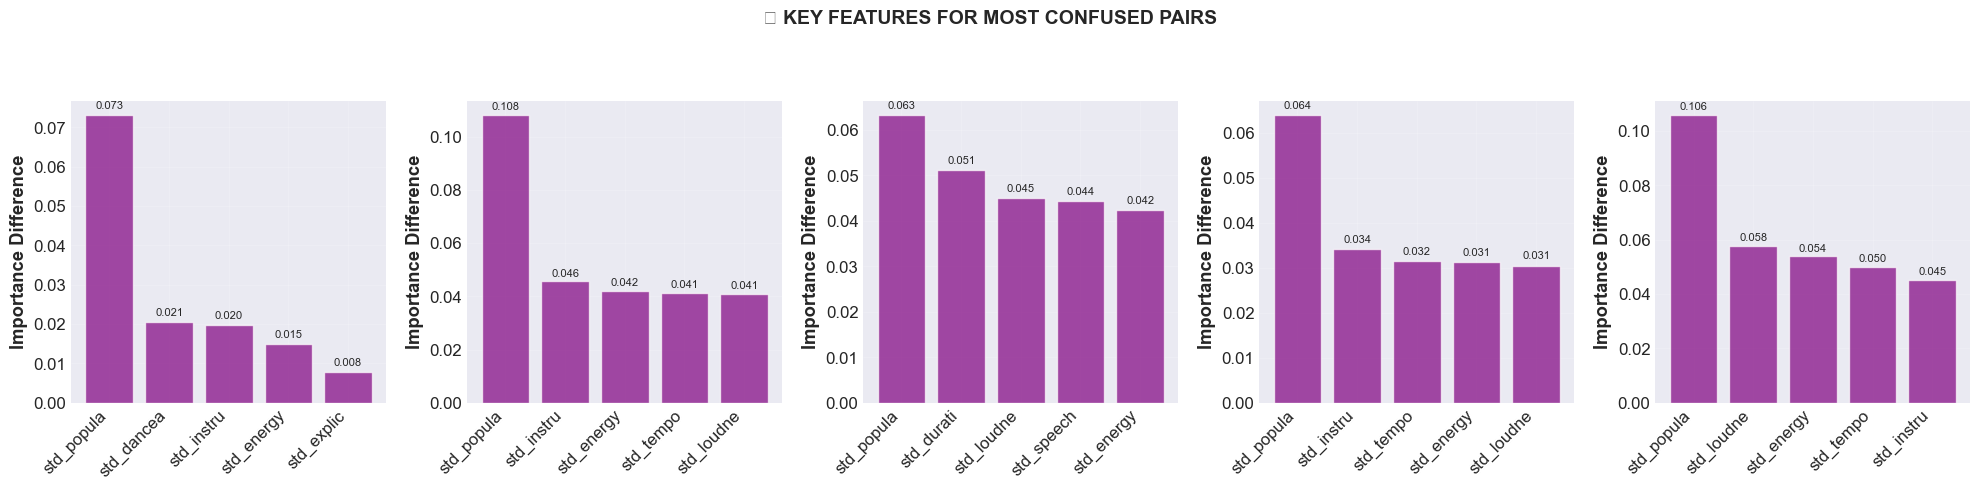


6️⃣ Creating Feature Importance Heatmap...


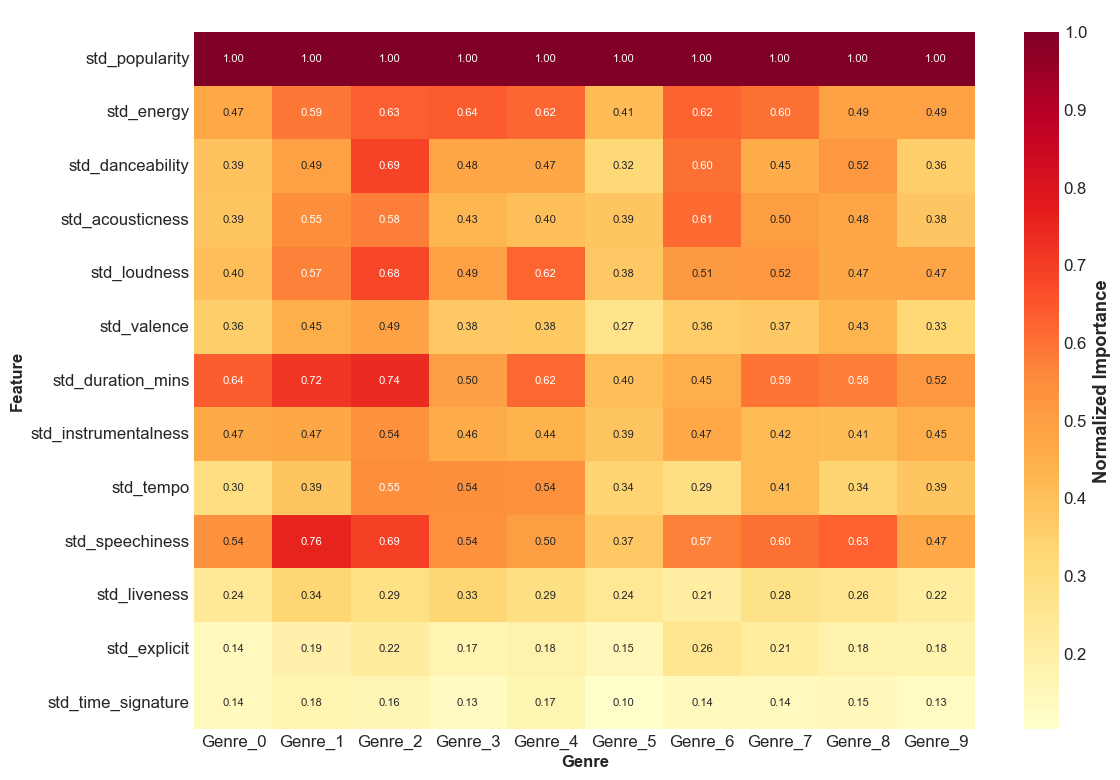


✅ EXPLAINABILITY ANALYSIS COMPLETED!

📊 KEY INSIGHTS:

🌟 TOP 5 MOST IMPORTANT FEATURES (Global):
   1. std_popularity: 0.1597 (±0.0077)
   2. std_energy: 0.1096 (±0.0075)
   3. std_danceability: 0.1085 (±0.0041)
   4. std_acousticness: 0.1052 (±0.0065)
   5. std_loudness: 0.0938 (±0.0041)

🎯 MOST DISCRIMINATIVE FEATURE PER GENRE:
   Genre_0: std_popularity (0.1094)
   Genre_1: std_popularity (0.1072)
   Genre_2: std_popularity (0.1421)
   Genre_3: std_popularity (0.0754)
   Genre_4: std_popularity (0.1153)
   Genre_5: std_popularity (0.1520)
   Genre_6: std_popularity (0.0828)
   Genre_7: std_popularity (0.1372)
   Genre_8: std_popularity (0.1513)
   Genre_9: std_popularity (0.2153)

📈 FEATURE IMPORTANCE STATISTICS:
   • Features with positive impact: 13/13
   • Average importance: 0.0728
   • Max importance: 0.1597
   • Total cumulative importance: 0.9463
   • Top 8 features explain 80% of model decisions

💾 Saving importance scores to CSV...
   Saved to: neural_network_feature_impor

In [15]:
# ===== NEURAL NETWORK EXPLAINABILITY - CELLA 2: VISUALIZZAZIONI =====
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("📊 GENERATING EXPLAINABILITY VISUALIZATIONS...")
print("="*70)

# ===== 1. GLOBAL FEATURE IMPORTANCE - STACKED BAR CHART =====
def plot_global_importance_stacked():
    """Permutation importance visualizzato come stacked bar"""

    # Prendi top 30 features
    importance_mean = perm_importance.importances_mean
    importance_std = perm_importance.importances_std

    # Ordina per importanza
    top_n = min(30, len(importance_mean))
    top_indices = np.argsort(importance_mean)[-top_n:][::-1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10))

    # Subplot 1: Importance con error bars
    y_pos = np.arange(len(top_indices))
    bars1 = ax1.barh(y_pos, importance_mean[top_indices],
                     xerr=importance_std[top_indices],
                     color='steelblue', alpha=0.8,
                     error_kw={'elinewidth': 1, 'alpha': 0.5})

    ax1.set_yticks(y_pos)
    ax1.set_yticklabels([feature_names[i] for i in top_indices])
    ax1.set_xlabel('Permutation Importance', fontsize=12)
    ax1.set_title('🌐 GLOBAL FEATURE IMPORTANCE - Top 30', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')

    # Aggiungi valori
    for i, (bar, val) in enumerate(zip(bars1, importance_mean[top_indices])):
        ax1.text(val + 0.0001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)

    # Subplot 2: Importanza cumulativa
    cumsum = np.cumsum(importance_mean[top_indices])
    cumsum_pct = cumsum / cumsum[-1] * 100

    bars2 = ax2.barh(y_pos, importance_mean[top_indices], color='coral', alpha=0.8)
    ax2_twin = ax2.twiny()
    ax2_twin.plot(cumsum_pct, y_pos, 'g-', linewidth=2, marker='o', markersize=4)

    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([feature_names[i] for i in top_indices])
    ax2.set_xlabel('Individual Importance', fontsize=12)
    ax2_twin.set_xlabel('Cumulative % of Total Importance', fontsize=12, color='green')
    ax2_twin.tick_params(axis='x', labelcolor='green')
    ax2.set_title('🎯 CUMULATIVE IMPORTANCE', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='x')

    # Linea 80%
    ax2_twin.axvline(x=80, color='red', linestyle='--', alpha=0.5, label='80% threshold')
    ax2_twin.legend()

    plt.tight_layout()
    plt.show()

    return top_indices

# ===== 2. PER-CLASS FEATURE IMPORTANCE PLOT =====
def plot_perclass_importance():
    """Visualizza importanza per ogni genre"""

    n_genres = gradient_importance.shape[0]
    fig, axes = plt.subplots(2, 5, figsize=(20, 10))
    axes = axes.flatten()

    for genre_idx in range(n_genres):
        ax = axes[genre_idx]

        # Top 10 features per questo genre
        importance = gradient_importance[genre_idx]
        top_10_idx = np.argsort(importance)[-10:][::-1]

        # Plot
        bars = ax.barh(range(10), importance[top_10_idx],
                      color=plt.cm.tab10(genre_idx/10), alpha=0.7)
        ax.set_yticks(range(10))
        ax.set_yticklabels([feature_names[i] for i in top_10_idx], fontsize=8)
        ax.set_xlabel('Gradient Importance', fontsize=9)
        ax.set_title(f'Genre_{genre_idx}', fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3, axis='x')

        # Aggiungi valori
        for bar, val in zip(bars, importance[top_10_idx]):
            ax.text(val + max(importance)*0.01, bar.get_y() + bar.get_height()/2,
                   f'{val:.3f}', va='center', fontsize=7)

    plt.suptitle('🎵 TOP-10 FEATURES PER GENRE (Gradient-based)', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 3. LOCAL EXPLAINABILITY - WATERFALL =====
def plot_waterfall_local(sample_idx=0):
    """Waterfall plot usando differenze di predizione"""

    print(f"   Creating Waterfall for sample {sample_idx}...")

    # Prendi un sample
    if hasattr(X_test, 'iloc'):
        sample = X_test.iloc[sample_idx:sample_idx+1].values
    else:
        sample = X_test_np[sample_idx:sample_idx+1]

    # Predizione originale
    original_pred = model.predict(sample, verbose=0)
    predicted_class = np.argmax(original_pred[0])
    base_prob = original_pred[0, predicted_class]

    # Calcola impatto di ogni feature tramite masking
    feature_impacts = []

    for feat_idx in range(sample.shape[1]):
        # Maschera questa feature con la media
        sample_masked = sample.copy()
        if hasattr(X_train, 'iloc'):
            mean_val = X_train.iloc[:, feat_idx].mean()
        else:
            mean_val = X_train_np[:, feat_idx].mean()
        sample_masked[0, feat_idx] = mean_val

        # Nuova predizione
        masked_pred = model.predict(sample_masked, verbose=0)
        impact = base_prob - masked_pred[0, predicted_class]
        feature_impacts.append(impact)

    # Ordina per impatto assoluto e prendi top 15
    feature_impacts = np.array(feature_impacts)
    top_15_idx = np.argsort(np.abs(feature_impacts))[-15:][::-1]

    # Crea waterfall plot
    fig, ax = plt.subplots(figsize=(12, 8))

    y_pos = np.arange(len(top_15_idx))
    impacts = feature_impacts[top_15_idx]
    colors = ['green' if x > 0 else 'red' for x in impacts]

    bars = ax.barh(y_pos, impacts, color=colors, alpha=0.7)

    # Labels
    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{feature_names[i]}\n(val={sample[0,i]:.2f})"
                       for i in top_15_idx], fontsize=9)

    # Valori sulle barre
    for bar, val in zip(bars, impacts):
        if abs(val) > 0.001:
            ax.text(val/2, bar.get_y() + bar.get_height()/2,
                   f'{val:.4f}', ha='center', va='center', fontsize=8,
                   color='white' if abs(val) > 0.01 else 'black')

    ax.set_title(f'🔍 WATERFALL EXPLANATION - Sample {sample_idx}\n' +
                f'Predicted: Genre_{predicted_class} (prob: {base_prob:.3f})\n' +
                f'True label: Genre_{y_test_encoded[sample_idx]}',
                fontsize=12, fontweight='bold')
    ax.set_xlabel('Impact on Prediction Probability', fontsize=11)
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
    ax.grid(True, alpha=0.3, axis='x')

    plt.tight_layout()
    plt.show()

    return feature_impacts, top_15_idx

# ===== 4. MULTIPLE WATERFALL COMPARISON =====
def plot_multiple_waterfalls(n_samples=3):
    """Confronta waterfall per più samples"""

    fig, axes = plt.subplots(1, n_samples, figsize=(18, 8))
    if n_samples == 1:
        axes = [axes]

    for idx, ax in enumerate(axes):
        # Sample
        if hasattr(X_test, 'iloc'):
            sample = X_test.iloc[idx:idx+1].values
        else:
            sample = X_test_np[idx:idx+1]

        # Predizione
        pred = model.predict(sample, verbose=0)
        pred_class = np.argmax(pred[0])
        base_prob = pred[0, pred_class]

        # Calcola impatti
        impacts = []
        for feat_idx in range(sample.shape[1]):
            sample_masked = sample.copy()
            if hasattr(X_train, 'iloc'):
                mean_val = X_train.iloc[:, feat_idx].mean()
            else:
                mean_val = X_train_np[:, feat_idx].mean()
            sample_masked[0, feat_idx] = mean_val
            masked_pred = model.predict(sample_masked, verbose=0)
            impact = base_prob - masked_pred[0, pred_class]
            impacts.append(impact)

        impacts = np.array(impacts)
        top_10_idx = np.argsort(np.abs(impacts))[-10:][::-1]

        # Plot
        values = impacts[top_10_idx]
        colors = ['green' if x > 0 else 'red' for x in values]

        bars = ax.barh(range(len(values)), values, color=colors, alpha=0.7)
        ax.set_yticks(range(len(values)))
        ax.set_yticklabels([feature_names[i] for i in top_10_idx], fontsize=8)
        ax.set_xlabel('Impact', fontsize=9)
        ax.set_title(f'Sample {idx}\nPred: G{pred_class} ({base_prob:.2f})\nTrue: G{y_test_encoded[idx]}',
                    fontsize=10, fontweight='bold')
        ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
        ax.grid(True, alpha=0.3, axis='x')

        # Valori
        for bar, val in zip(bars, values):
            if abs(val) > 0.001:
                ax.text(val/2, bar.get_y() + bar.get_height()/2,
                       f'{val:.3f}', ha='center', va='center', fontsize=7,
                       color='white' if abs(val) > 0.01 else 'black')

    plt.suptitle('🔍 LOCAL EXPLANATIONS COMPARISON', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 5. CONFUSION IMPORTANCE MATRIX =====
def plot_confusion_importance():
    """Mostra quali features distinguono meglio tra classi confuse"""

    # Calcola confusion matrix
    y_pred = model.predict(X_test_np, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    cm = confusion_matrix(y_test_encoded, y_pred_classes)

    # Trova le coppie più confuse
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)

    # Top 5 coppie confuse
    confusion_pairs = []
    for i in range(10):
        for j in range(10):
            if i != j:
                confusion_pairs.append((cm_no_diag[i,j], i, j))

    confusion_pairs.sort(reverse=True)
    top_pairs = confusion_pairs[:5]

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for idx, (count, true_class, pred_class) in enumerate(top_pairs):
        ax = axes[idx]

        # Features che distinguono meglio tra queste due classi
        diff_importance = np.abs(gradient_importance[true_class] - gradient_importance[pred_class])
        top_5_idx = np.argsort(diff_importance)[-5:][::-1]

        bars = ax.bar(range(5), diff_importance[top_5_idx], color='purple', alpha=0.7)
        ax.set_xticks(range(5))
        ax.set_xticklabels([feature_names[i][:10] for i in top_5_idx], rotation=45, ha='right')
        ax.set_ylabel('Importance Difference')
        ax.set_title(f'G{true_class}→G{pred_class}\n({count} errors)', fontweight='bold')
        ax.grid(True, alpha=0.3, axis='y')

        # Valori
        for bar, val in zip(bars, diff_importance[top_5_idx]):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                   f'{val:.3f}', ha='center', va='bottom', fontsize=8)

    plt.suptitle('🔄 KEY FEATURES FOR MOST CONFUSED PAIRS', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ===== 6. IMPORTANCE HEATMAP =====
def plot_importance_heatmap():
    """Heatmap di importanza features vs genres"""

    # Normalizza gradient importance per visualizzazione
    grad_norm = gradient_importance / gradient_importance.max(axis=1, keepdims=True)

    # Prendi top 20 features globalmente importanti
    global_importance = perm_importance.importances_mean
    top_20_idx = np.argsort(global_importance)[-20:][::-1]

    # Crea heatmap
    fig, ax = plt.subplots(figsize=(12, 8))

    sns.heatmap(grad_norm[:, top_20_idx].T,
                xticklabels=[f'Genre_{i}' for i in range(10)],
                yticklabels=[feature_names[i] for i in top_20_idx],
                cmap='YlOrRd', cbar_kws={'label': 'Normalized Importance'},
                annot=True, fmt='.2f', annot_kws={'size': 8})

    ax.set_title('🗺️ FEATURE IMPORTANCE HEATMAP (Top 20 Features)',
                fontsize=14, fontweight='bold')
    ax.set_xlabel('Genre', fontsize=12)
    ax.set_ylabel('Feature', fontsize=12)

    plt.tight_layout()
    plt.show()

# ===== MAIN EXECUTION =====
print("\n1️⃣ Creating Global Feature Importance...")
top_features = plot_global_importance_stacked()

print("\n2️⃣ Creating Per-Genre Feature Importance...")
plot_perclass_importance()

print("\n3️⃣ Creating Waterfall Plot for Sample 0...")
impacts, top_idx = plot_waterfall_local(sample_idx=0)

print("\n4️⃣ Creating Multiple Waterfall Comparisons...")
plot_multiple_waterfalls(n_samples=3)

print("\n5️⃣ Creating Confusion Importance Analysis...")
plot_confusion_importance()

print("\n6️⃣ Creating Feature Importance Heatmap...")
plot_importance_heatmap()

# ===== SUMMARY REPORT =====
print("\n✅ EXPLAINABILITY ANALYSIS COMPLETED!")
print("="*70)

print("\n📊 KEY INSIGHTS:")
print("\n🌟 TOP 5 MOST IMPORTANT FEATURES (Global):")
importance_mean = perm_importance.importances_mean
importance_std = perm_importance.importances_std
top_5_global = np.argsort(importance_mean)[-5:][::-1]

for i, idx in enumerate(top_5_global, 1):
    print(f"   {i}. {feature_names[idx]}: {importance_mean[idx]:.4f} (±{importance_std[idx]:.4f})")

print("\n🎯 MOST DISCRIMINATIVE FEATURE PER GENRE:")
for genre_idx in range(10):
    importance = gradient_importance[genre_idx]
    top_feature_idx = np.argmax(importance)
    print(f"   Genre_{genre_idx}: {feature_names[top_feature_idx]} ({importance[top_feature_idx]:.4f})")

print("\n📈 FEATURE IMPORTANCE STATISTICS:")
total_importance = np.sum(importance_mean)
positive_features = np.sum(importance_mean > 0)
print(f"   • Features with positive impact: {positive_features}/{len(importance_mean)}")
print(f"   • Average importance: {np.mean(importance_mean):.4f}")
print(f"   • Max importance: {np.max(importance_mean):.4f}")
print(f"   • Total cumulative importance: {total_importance:.4f}")

# Trova quante features servono per 80% importanza
cumsum = np.cumsum(np.sort(importance_mean)[::-1])
n_features_80 = np.argmax(cumsum >= 0.8 * total_importance) + 1
print(f"   • Top {n_features_80} features explain 80% of model decisions")

# ===== SALVA RISULTATI =====
print("\n💾 Saving importance scores to CSV...")

# DataFrame con tutte le info
importance_df = pd.DataFrame({
    'feature': feature_names,
    'global_importance_mean': importance_mean,
    'global_importance_std': importance_std
})

# Aggiungi importanza per genre
for genre_idx in range(10):
    importance_df[f'genre_{genre_idx}_importance'] = gradient_importance[genre_idx]

# Ordina per importanza globale
importance_df = importance_df.sort_values('global_importance_mean', ascending=False)

# Salva
importance_df.to_csv('neural_network_feature_importance.csv', index=False)
print("   Saved to: neural_network_feature_importance.csv")

print("\n💡 INTERPRETATION GUIDE:")
print("   • Global Importance: How much accuracy drops when feature is shuffled")
print("   • Gradient Importance: How sensitive each genre is to feature changes")
print("   • Waterfall: Shows feature contributions to individual predictions")
print("   • Green bars = increase prediction probability")
print("   • Red bars = decrease prediction probability")
print("   • Heatmap: Shows which features are important for which genres")

print("\n🎉 Analysis complete! Check the 6 generated plots for insights.")


### SHAP Explainability del Random Forest Model

#### SHAP Calculations

In [16]:
# CELLA 1 - Calcolo SHAP Values
import shap
import numpy as np
import pandas as pd

print("=" * 60)
print("INIZIALIZZAZIONE ANALISI SHAP")
print("=" * 60)

# Preparazione dati - CONVERSIONE CORRETTA
print("\n📊 Preparazione dati...")
X_explain = X_test[:500]

# CONVERSIONE CORRETTA di y_test
if hasattr(y_test, 'iloc'):
    # Se è una Series pandas
    y_explain = y_test.iloc[:500].values
else:
    # Se è già un array
    y_explain = y_test[:500]

# Assicurati che sia un array di stringhe
if hasattr(y_explain[0], 'decode'):
    y_explain = [str(x) for x in y_explain]
else:
    y_explain = np.array(y_explain).astype(str)

feature_names = X_train.columns.tolist()

print(f"  - X_explain shape: {X_explain.shape}")
print(f"  - y_explain type: {type(y_explain)}")
print(f"  - y_explain length: {len(y_explain)}")
print(f"  - Primo elemento y_explain: {y_explain[0]}")
print(f"  - Numero features: {len(feature_names)}")

# Calcolo SHAP
print("\n📊 Calcolando SHAP values...")
explainer = shap.TreeExplainer(best_rf_model)
shap_values = explainer.shap_values(X_explain)

# Info risultati
print(f"\n✓ SHAP completato!")
print(f"  - Classi del modello: {list(best_rf_model.classes_)}")

# Gestione formato SHAP values
if hasattr(shap_values, 'shape'):
    print(f"  - SHAP values shape: {shap_values.shape}")
    if len(shap_values.shape) == 3:
        # Formato 3D: (samples, features, classes)
        n_samples, n_features, n_classes = shap_values.shape
        print(f"    Format: ({n_samples} samples, {n_features} features, {n_classes} classes)")

        # Converti in lista di array 2D
        shap_values_list = []
        for class_idx in range(n_classes):
            shap_values_list.append(shap_values[:, :, class_idx])
        shap_values = shap_values_list
        print(f"  - Convertito in lista di {len(shap_values)} array")
elif isinstance(shap_values, list):
    print(f"  - SHAP values: lista di {len(shap_values)} array")
    print(f"  - Shape primo elemento: {shap_values[0].shape}")

print("\n" + "=" * 60)

INIZIALIZZAZIONE ANALISI SHAP

📊 Preparazione dati...
  - X_explain shape: (500, 13)
  - y_explain type: <class 'numpy.ndarray'>
  - y_explain length: 500
  - Primo elemento y_explain: Hip-Hop & R&B
  - Numero features: 13

📊 Calcolando SHAP values...

✓ SHAP completato!
  - Classi del modello: ['Classical/Ambient & Stage', 'Country/Folk & Songwriter', 'Electronic & Dance', 'Hip-Hop & R&B', 'Jazz/Soul/Funk/Blues', 'Latin & Brazilian', 'Metal & Hardcore', 'Pop & Indie', 'Rock & Alternative', 'World & Regional']
  - SHAP values shape: (500, 13, 10)
    Format: (500 samples, 13 features, 10 classes)
  - Convertito in lista di 10 array



#### SHAP Visualizations

ANALISI GLOBALE - STACKED BAR CHART

Calcolando importanza per ogni classe...
  Classe 0 (Classical/Ambient & Stage): calcolata
  Classe 1 (Country/Folk & Songwriter): calcolata
  Classe 2 (Electronic & Dance): calcolata
  Classe 3 (Hip-Hop & R&B): calcolata
  Classe 4 (Jazz/Soul/Funk/Blues): calcolata
  Classe 5 (Latin & Brazilian): calcolata
  Classe 6 (Metal & Hardcore): calcolata
  Classe 7 (Pop & Indie): calcolata
  Classe 8 (Rock & Alternative): calcolata
  Classe 9 (World & Regional): calcolata

✓ Matrice importanza creata: (13, 10)


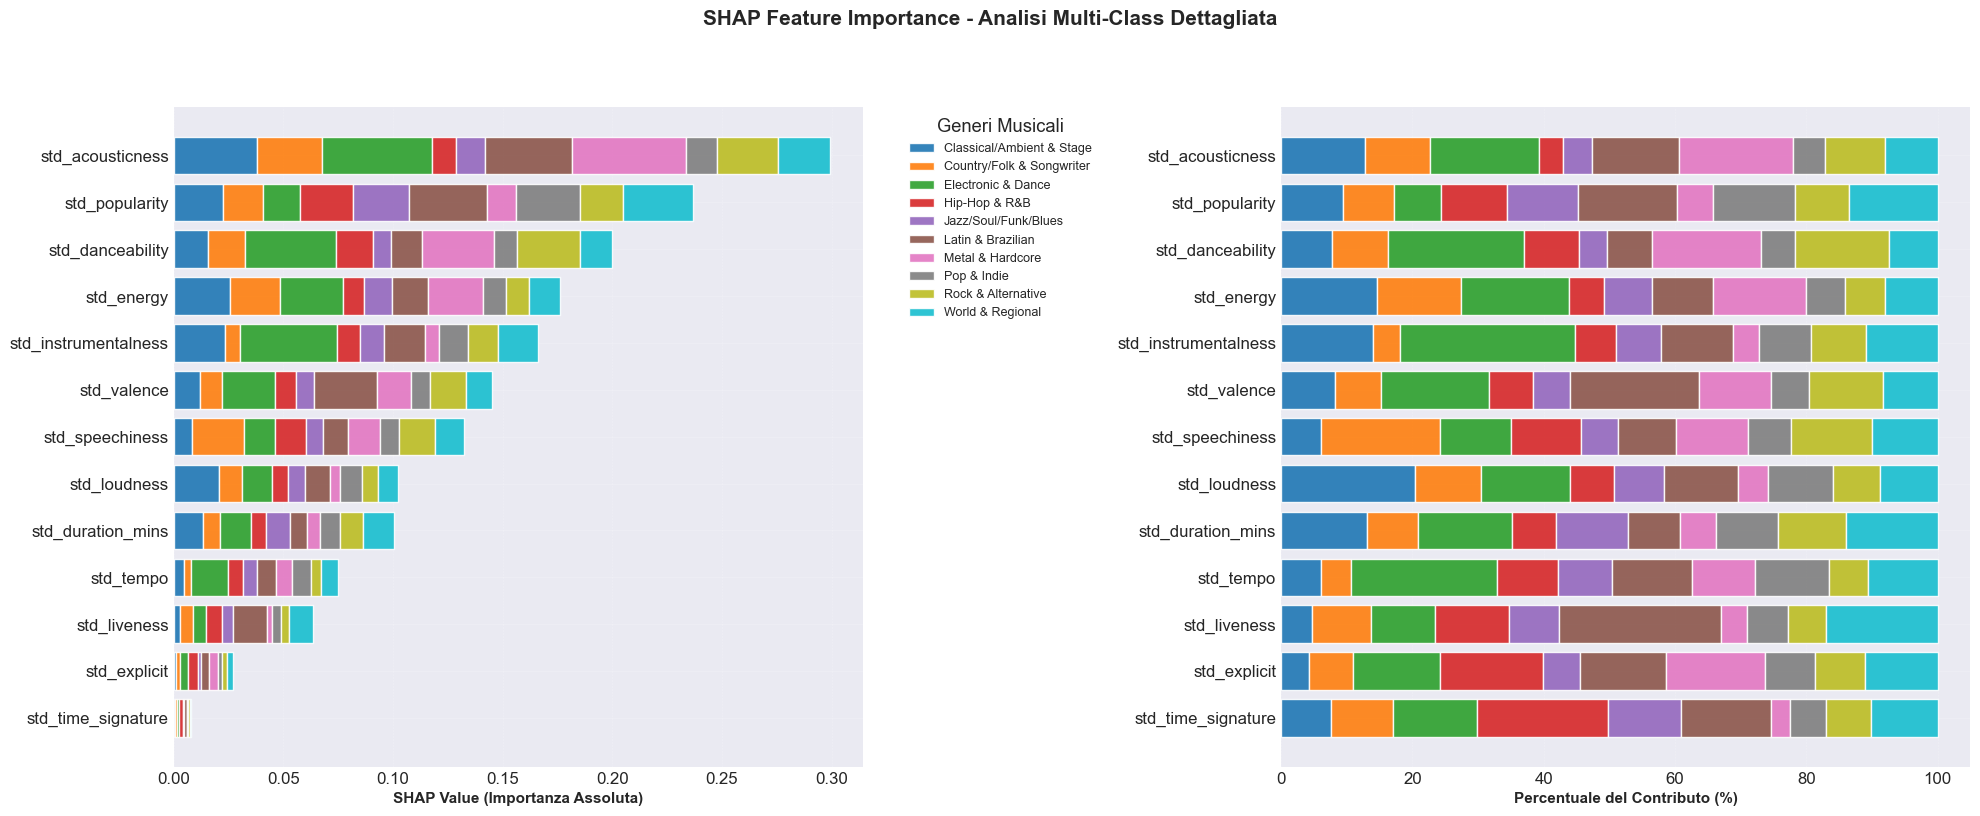


📊 ANALISI DETTAGLIATA:
------------------------------------------------------------

🏆 TOP 5 FEATURES PIÙ IMPORTANTI (somma su tutte le classi):
  1. std_instrumentalness: 0.166116
  2. std_energy          : 0.176339
  3. std_danceability    : 0.199932
  4. std_popularity      : 0.236947
  5. std_acousticness    : 0.299412

🎯 FEATURE PIÙ IMPORTANTE PER OGNI GENERE:
  Classical/Ambient & Stage      → std_acousticness     (0.0381)
  Country/Folk & Songwriter      → std_acousticness     (0.0296)
  Electronic & Dance             → std_acousticness     (0.0498)
  Hip-Hop & R&B                  → std_popularity       (0.0240)
  Jazz/Soul/Funk/Blues           → std_popularity       (0.0256)
  Latin & Brazilian              → std_acousticness     (0.0397)
  Metal & Hardcore               → std_acousticness     (0.0520)
  Pop & Indie                    → std_popularity       (0.0295)
  Rock & Alternative             → std_danceability     (0.0287)
  World & Regional               → std_popular

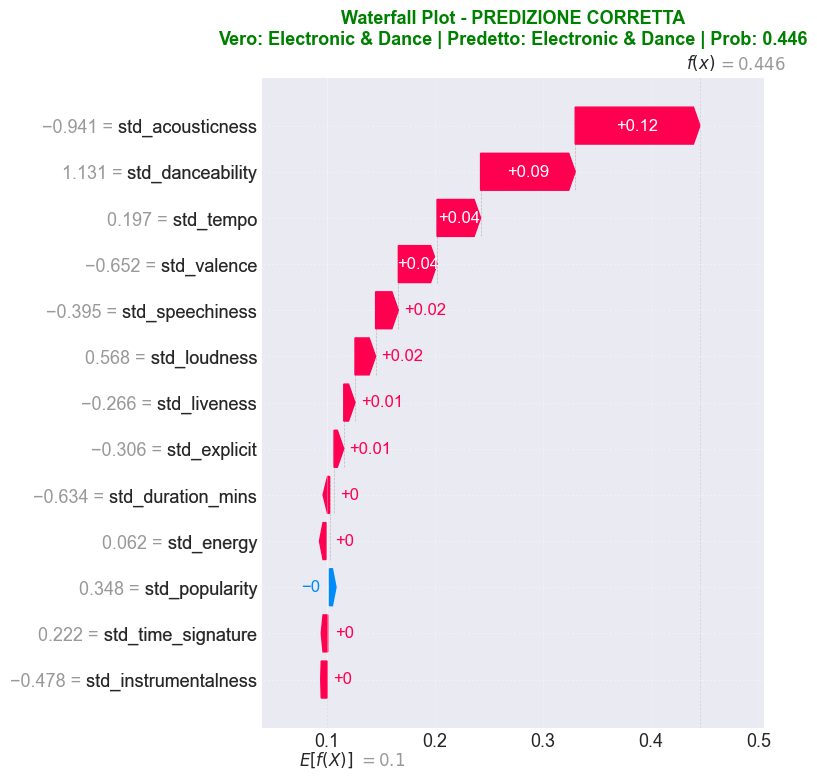


  Top 5 features più influenti per questa predizione:
    ↑ AUMENTA probabilità di 'Electronic & Dance': std_acousticness     (SHAP: +0.1157)
    ↑ AUMENTA probabilità di 'Electronic & Dance': std_danceability     (SHAP: +0.0878)
    ↑ AUMENTA probabilità di 'Electronic & Dance': std_tempo            (SHAP: +0.0404)
    ↑ AUMENTA probabilità di 'Electronic & Dance': std_valence          (SHAP: +0.0359)
    ↑ AUMENTA probabilità di 'Electronic & Dance': std_speechiness      (SHAP: +0.0211)

--- ESEMPIO 2 (Sample #0) ---
  Genere VERO: Hip-Hop & R&B
  Genere PREDETTO: Latin & Brazilian
  Probabilità: 0.205


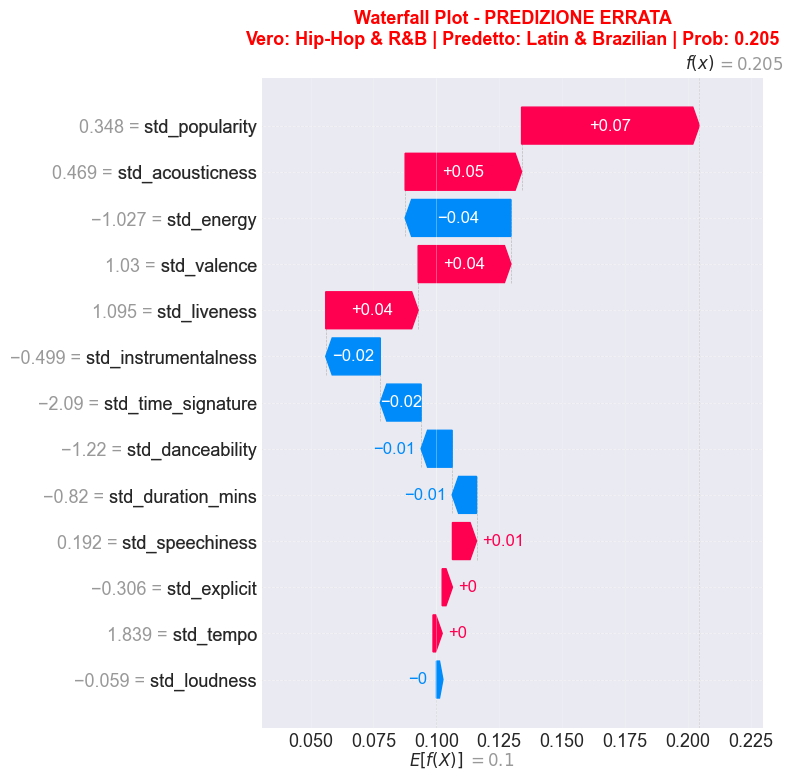


  Top 5 features più influenti per questa predizione:
    ↑ AUMENTA probabilità di 'Latin & Brazilian': std_popularity       (SHAP: +0.0706)
    ↑ AUMENTA probabilità di 'Latin & Brazilian': std_acousticness     (SHAP: +0.0463)
    ↓ DIMINUISCE probabilità di 'Latin & Brazilian': std_energy           (SHAP: -0.0420)
    ↑ AUMENTA probabilità di 'Latin & Brazilian': std_valence          (SHAP: +0.0369)
    ↑ AUMENTA probabilità di 'Latin & Brazilian': std_liveness         (SHAP: +0.0367)

ANALISI COMPLETATA!


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

print("=" * 60)
print("ANALISI GLOBALE - STACKED BAR CHART")
print("=" * 60)

# Calcola importanza PER OGNI CLASSE SEPARATAMENTE
print("\nCalcolando importanza per ogni classe...")

class_names = best_rf_model.classes_
n_classes = len(shap_values)
n_features = shap_values[0].shape[1]

# Matrice: righe = features, colonne = classi
importance_matrix = np.zeros((n_features, n_classes))

for class_idx in range(n_classes):
    # Importanza media assoluta per questa classe
    importance_matrix[:, class_idx] = np.abs(shap_values[class_idx]).mean(axis=0)
    print(f"  Classe {class_idx} ({class_names[class_idx]}): calcolata")

# Crea DataFrame per gestione più facile
importance_df = pd.DataFrame(
    importance_matrix,
    index=feature_names[:n_features],
    columns=class_names
)

# Calcola importanza totale per ordinare le features
total_importance = importance_df.sum(axis=1).sort_values(ascending=True)

# Riordina il DataFrame secondo l'importanza totale
importance_df = importance_df.loc[total_importance.index]

print(f"\n✓ Matrice importanza creata: {importance_df.shape}")

# ========== STACKED BAR CHART ==========
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# --- SUBPLOT 1: Stacked Bar Chart (valori assoluti) ---
# Colori distintivi per ogni classe (10 colori diversi)
colors = plt.cm.tab10(np.linspace(0, 1, n_classes))

# Plot stacked bars
bottom_pos = np.zeros(n_features)
for class_idx, class_name in enumerate(class_names):
    values = importance_df[class_name].values
    bars = ax1.barh(range(n_features), values,
                    left=bottom_pos,
                    color=colors[class_idx],
                    label=class_name,
                    alpha=0.9)
    bottom_pos += values

# Personalizzazione subplot 1
ax1.set_yticks(range(n_features))
ax1.set_yticklabels(importance_df.index)
ax1.set_xlabel('SHAP Value (Importanza Assoluta)', fontsize=11, fontweight='bold')
ax1.set_title('🎵 Contributo di ogni Genere all\'Importanza delle Features',
              fontsize=13, fontweight='bold')
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left',
           fontsize=9, title='Generi Musicali')
ax1.grid(axis='x', alpha=0.3, linestyle='--')

# --- SUBPLOT 2: Stacked Bar Chart (percentuali) ---
# Normalizza per riga (100% per ogni feature)
importance_df_norm = importance_df.div(importance_df.sum(axis=1), axis=0) * 100

bottom_pos = np.zeros(n_features)
for class_idx, class_name in enumerate(class_names):
    values = importance_df_norm[class_name].values
    bars = ax2.barh(range(n_features), values,
                    left=bottom_pos,
                    color=colors[class_idx],
                    alpha=0.9)
    bottom_pos += values

# Personalizzazione subplot 2
ax2.set_yticks(range(n_features))
ax2.set_yticklabels(importance_df.index)
ax2.set_xlabel('Percentuale del Contributo (%)', fontsize=11, fontweight='bold')
ax2.set_title('📊 Distribuzione Percentuale del Contributo per Feature',
              fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.3, linestyle='--')

plt.suptitle('SHAP Feature Importance - Analisi Multi-Class Dettagliata',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ========== ANALISI NUMERICA ==========
print("\n" + "=" * 60)
print("📊 ANALISI DETTAGLIATA:")
print("-" * 60)

# Top features per importanza totale
print("\n🏆 TOP 5 FEATURES PIÙ IMPORTANTI (somma su tutte le classi):")
for i, (feat, val) in enumerate(total_importance.tail(5).items(), 1):
    print(f"  {i}. {feat:20s}: {val:.6f}")

# Feature più importante per ogni genere
print("\n🎯 FEATURE PIÙ IMPORTANTE PER OGNI GENERE:")
for class_name in class_names:
    top_feature = importance_df[class_name].idxmax()
    value = importance_df[class_name].max()
    print(f"  {class_name:30s} → {top_feature:20s} ({value:.4f})")

print("\n" + "=" * 60)

# %%
# CELLA 3 - Waterfall Plots per Esempi Specifici
print("\n" + "=" * 60)
print("WATERFALL PLOTS - ANALISI LOCALE")
print("=" * 60)

# Helper per indicizzare in modo sicuro riga i-esima sia per DataFrame che per ndarray
def get_row_block(X, i):
    return X.iloc[[i]] if hasattr(X, "iloc") else X[i:i+1]

def get_row_vector(X, i):
    return X.iloc[i] if hasattr(X, "iloc") else X[i]

def get_y_value(y, i):
    return y.iloc[i] if hasattr(y, "iloc") else y[i]

# Helper per ricavare gli SHAP values della classe predetta (compatibile con formati diversi)
def get_sample_shap(shap_values, classes, pred_class_idx, sample_idx):
    import numpy as _np
    # Caso classico: lista per classe -> [n_classes][n_samples, n_features]
    if isinstance(shap_values, list):
        return _np.asarray(shap_values[pred_class_idx][sample_idx])
    # Caso Explanation globale (shap.Explanation) con .values
    if hasattr(shap_values, "values"):
        vals = shap_values.values
        if vals.ndim == 3 and vals.shape[-1] == len(classes):
            return _np.asarray(vals[sample_idx, :, pred_class_idx])
        if vals.ndim == 2:
            return _np.asarray(vals[sample_idx])
    # Caso array numpy
    if isinstance(shap_values, _np.ndarray):
        if shap_values.ndim == 3:
            # (n_classes, n_samples, n_features) oppure (n_samples, n_features, n_classes)
            if shap_values.shape[0] == len(classes):
                return _np.asarray(shap_values[pred_class_idx, sample_idx, :])
            if shap_values.shape[-1] == len(classes):
                return _np.asarray(shap_values[sample_idx, :, pred_class_idx])
        if shap_values.ndim == 2:
            return _np.asarray(shap_values[sample_idx])
    raise ValueError("Formato di shap_values non riconosciuto per il plotting.")

# Trova esempi interessanti: uno corretto e uno sbagliato
correct_examples, wrong_examples = [], []
to_check = min(100, len(y_explain))
is_df = hasattr(X_explain, "iloc")

for i in range(to_check):
    pred_i = best_rf_model.predict(get_row_block(X_explain, i))[0]
    true_i = get_y_value(y_explain, i)
    if pred_i == true_i and len(correct_examples) < 2:
        correct_examples.append(i)
    elif pred_i != true_i and len(wrong_examples) < 2:
        wrong_examples.append(i)
    if len(correct_examples) >= 2 and len(wrong_examples) >= 2:
        break

examples_to_plot = correct_examples[:1] + wrong_examples[:1]  # 1 corretto + 1 sbagliato
print(f"Analizzando {len(examples_to_plot)} esempi selezionati...")

classes = list(best_rf_model.classes_)

# Deriva i nomi feature in modo robusto
if 'feature_names' in globals() and feature_names is not None:
    all_feature_names = list(feature_names)
elif is_df:
    all_feature_names = list(X_explain.columns)
else:
    # fallback generico se non disponibile
    n_feat_guess = get_row_block(X_explain, 0).shape[1]
    all_feature_names = [f"f{i}" for i in range(n_feat_guess)]

for plot_idx, sample_idx in enumerate(examples_to_plot, 1):
    print(f"\n--- ESEMPIO {plot_idx} (Sample #{sample_idx}) ---")

    # Predizione
    sample_data = get_row_block(X_explain, sample_idx)
    pred_class = best_rf_model.predict(sample_data)[0]
    pred_proba = best_rf_model.predict_proba(sample_data)[0]
    true_class = get_y_value(y_explain, sample_idx)

    # Indice della classe predetta
    pred_class_idx = classes.index(pred_class)

    print(f"  Genere VERO: {true_class}")
    print(f"  Genere PREDETTO: {pred_class}")
    print(f"  Probabilità: {pred_proba[pred_class_idx]:.3f}")

    # SHAP values per la classe predetta
    sample_shap = get_sample_shap(shap_values, classes, pred_class_idx, sample_idx)

    # Base value
    ev = explainer.expected_value
    if isinstance(ev, (list, tuple, np.ndarray)):
        base_value = ev[pred_class_idx]
    else:
        base_value = ev

    # Prepara la riga dati coerente con la lunghezza di sample_shap
    row_vec = get_row_vector(X_explain, sample_idx)
    k = min(len(all_feature_names), len(sample_shap))
    fnames = all_feature_names[:k]
    if is_df:
        data_vec = row_vec[fnames]
    else:
        data_vec = row_vec[:k]

    # Crea Explanation
    shap_exp = shap.Explanation(
        values=sample_shap[:k],
        base_values=base_value,
        data=data_vec,
        feature_names=fnames
    )

    # WATERFALL PLOT
    plt.figure(figsize=(14, 7))
    shap.waterfall_plot(shap_exp, max_display=min(13, k), show=False)

    # Titolo informativo
    if pred_class == true_class:
        status = "PREDIZIONE CORRETTA"
        color_title = 'green'
    else:
        status = "PREDIZIONE ERRATA"
        color_title = 'red'

    plt.title(
        f'Waterfall Plot - {status}\n'
        f'Vero: {true_class} | Predetto: {pred_class} | Prob: {pred_proba[pred_class_idx]:.3f}',
        fontsize=13, fontweight='bold', color=color_title
    )

    plt.tight_layout()
    plt.show()

    # Analisi features più influenti
    feature_impacts = sorted(zip(fnames, sample_shap[:k]), key=lambda x: abs(x[1]), reverse=True)

    print("\n  Top 5 features più influenti per questa predizione:")
    for feat, impact in feature_impacts[:5]:
        direction = "↑ AUMENTA" if impact > 0 else "↓ DIMINUISCE"
        # ANSI colors: verde/rosso
        color = '\033[92m' if impact > 0 else '\033[91m'
        print(f"    {color}{direction}\033[0m probabilità di '{pred_class}': {feat:20s} (SHAP: {impact:+.4f})")

print("\n" + "=" * 60)
print("ANALISI COMPLETATA!")
print("=" * 60)
